# 03 - Routing Beats Latency (Imagenette Math Corruptions)

## 1. Setup and Mathematical Corruptions


In [1]:
import os, time, copy, random, warnings, gc
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

from torchvision import models, transforms
import matplotlib.pyplot as plt
from transformers import AutoModelForImageClassification, AutoConfig, logging as hf_logging
hf_logging.set_verbosity_error()

from tqdm.auto import tqdm

# ---- Paths -----------------------------------------------------------------
# Portable PROJECT_ROOT resolution
if os.path.exists("outputs_imagenette_math"):
    PROJECT_ROOT = os.path.abspath(".")
elif os.path.exists(os.path.join("..", "outputs_imagenette_math")):
    PROJECT_ROOT = os.path.abspath("..")
elif os.path.exists(r"d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math"):
    PROJECT_ROOT = r"d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2"
else:
    PROJECT_ROOT = os.path.abspath("..")
# Portable DATA_DIR with local fallback
CLEAN_DATA_DIR = os.environ.get("IMAGENETTE_DIR", os.path.join(PROJECT_ROOT, "data", "imagenette"))
if not os.path.exists(CLEAN_DATA_DIR) and os.path.exists(r"d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\data\imagenette"):
    CLEAN_DATA_DIR = r"d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\data\imagenette"
TRAIN_DIR   = os.path.join(CLEAN_DATA_DIR, "train")
VAL_DIR     = os.path.join(CLEAN_DATA_DIR, "val")

OUTPUT_DIR     = os.path.normpath(os.path.join(PROJECT_ROOT, "outputs_imagenette_math"))
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
CACHE_DIR      = os.path.join(OUTPUT_DIR, "cache")
GATER_DIR      = os.path.join(OUTPUT_DIR, "gaters")
PLOTS_DIR      = os.path.join(OUTPUT_DIR, "plots")
RESULTS_XLSX   = os.path.join(OUTPUT_DIR, "results_imagenette_math.xlsx")
for d in [CHECKPOINT_DIR, CACHE_DIR, GATER_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ---- Config ----------------------------------------------------------------
NUM_CLASSES    = 10
IMG_SIZE       = 384
GATER_IMG_SIZE = 64
EXPERT_CACHE_SIZE = 224
AUX_LOSS_WEIGHT  = 0.0    # Fix3: keep light oracle-imitation signal through joint training
GATER_DROPOUT    = 0.25   # C5: regularize the thin gater head
WARMSTART_EPOCHS = 8      # C3: imitation-learning warm start before joint Gumbel training
LAM_WARMUP_FRAC  = 0.3    # Fix5: fraction of each gater's epochs spent at lam=1.0 before annealing
WIPE_STALE_CACHE = False  # Set to True only when you explicitly want to wipe CACHE_DIR and recompute

# ---- Gater redesign: pure image-only, first-touch router -------------------
GATER_LATENCY_BUDGET_FRAC = 0.6

ALL_CORRUPTIONS = ["blur", "noise", "jpeg", "contrast", "speckle"]
SEVERITY_LEVELS = ["clean", "moderate", "severe"]

BATCH_SIZE        = 128
EPOCHS_EXPERT     = 50   # Shorter because we use massive mixed pool
PATIENCE_EXPERT   = 5
EPOCHS_GATER      = 50
PATIENCE_GATER    = 10
GATER_VAL_FRAC    = 0.15
GATER_VAL_SEED    = 123
LR_EXPERT         = 4e-4
LR_GATER          = 5e-5
CLASS_LOSS_SCALE  = float(np.log(NUM_CLASSES))  # C2: rescale so class_loss and norm_lat_loss are ~O(1)
GUMBEL_TAU_START  = 1.0
GUMBEL_TAU_END    = 0.1

LAMBDAS = [0.5, 0.6, 0.7, 0.8, 0.9, 0.92, 0.95, 0.97, 1.0]  # C1: widened grid, full Pareto sweep
SEEDS   = [0, 1, 2]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

# ---- Mathematical Corruptions ----------------------------------------------
def _clip_uint8(img):
    return np.clip(img, 0, 255).astype(np.uint8)

_BLUR_PARAMS = {"clean": None, "moderate": (11, 5.0), "severe": (21, 10.0)}
def apply_gaussian_blur(img, severity):
    p = _BLUR_PARAMS[severity]
    return img if p is None else cv2.GaussianBlur(img, (p[0], p[0]), p[1])

_NOISE_STD = {"clean": 0.0, "moderate": 0.20, "severe": 0.50}
def apply_gaussian_noise(img, severity):
    std = _NOISE_STD[severity] * 255.0
    if std == 0.0: return img
    return _clip_uint8(img.astype(np.float32) + np.random.normal(0, std, img.shape))

_JPEG_QUALITY = {"clean": 100, "moderate": 5, "severe": 1}
def apply_jpeg_compression(img, severity):
    q = _JPEG_QUALITY[severity]
    if q >= 100: return img
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    ok, enc = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])
    dec = cv2.imdecode(enc, cv2.IMREAD_COLOR)
    return cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)

_CONTRAST_FACTOR = {"clean": 1.0, "moderate": 0.10, "severe": 0.02}
def apply_contrast_shift(img, severity):
    f = _CONTRAST_FACTOR[severity]
    if f == 1.0: return img
    mean = img.mean()
    return _clip_uint8((img.astype(np.float32) - mean) * f + mean)

_SPECKLE_VAR = {"clean": 0.0, "moderate": 0.5, "severe": 1.0}
def apply_speckle_noise(img, severity):
    v = _SPECKLE_VAR[severity]
    if v == 0.0: return img
    noise = np.random.normal(0, v ** 0.5, img.shape)
    return _clip_uint8(img.astype(np.float32) * (1.0 + noise))

CORRUPTION_FUNCS = {
    "blur": apply_gaussian_blur, "noise": apply_gaussian_noise,
    "jpeg": apply_jpeg_compression, "contrast": apply_contrast_shift, "speckle": apply_speckle_noise,
}

def apply_corruption(img_array, corruption, severity):
    return img_array if severity == "clean" else CORRUPTION_FUNCS[corruption](img_array, severity)

# No-op 1-to-1 mapping for Imagenette
SUPERCLASS_MAP = torch.arange(NUM_CLASSES, dtype=torch.long)

## 1b. Wipe Stale Cache / Gater Artifacts (A1)

Critical: every parameter above (GATER_IMG_SIZE, benchmark method, Gater architecture, LAMBDAS) changed since the last run. All downstream cells guard with `if os.path.exists(...): skip`, so **any leftover `.pt` file from the old run will be silently reused** and quietly reproduce the old broken numbers. This cell forces a clean slate for the cache and gater directories (expert checkpoints in `CHECKPOINT_DIR` are untouched since expert training config didn't change).

In [2]:
import shutil

if WIPE_STALE_CACHE:
    for d in [CACHE_DIR]:
        shutil.rmtree(d, ignore_errors=True)
        os.makedirs(d, exist_ok=True)
    print("Wiped stale CACHE_DIR (GATER_DIR protected). CHECKPOINT_DIR (experts) left intact.")
else:
    print("WIPE_STALE_CACHE is False -- preserving existing cache, checkpoints, and gater artifacts.")

WIPE_STALE_CACHE is False -- preserving existing cache, checkpoints, and gater artifacts.


## 2. GPU Dataset & Models

In [3]:
import torchvision.datasets as torchvision_datasets

def get_test_samples(train_dir):
    """Deterministically retrieve the 20% test partition samples without building full training pool."""
    clean_ds = torchvision_datasets.ImageFolder(train_dir, transform=None)
    generator = torch.Generator().manual_seed(42)
    train_len = int(0.8 * len(clean_ds))
    test_len = len(clean_ds) - train_len
    _, test_ds = torch.utils.data.random_split(clean_ds, [train_len, test_len], generator=generator)
    return [clean_ds.samples[i] for i in test_ds.indices]

class GPUMathCorruptPool: 
    def __init__(self, train_dir, device=None, clean_only=False, rand_aug_mag=9):
        self.device = device or DEVICE
        print("  Loading Imagenette to RAM, applying math corruptions (60% clean, 20% mod, 20% sev), and moving to VRAM...")
        clean_ds = torchvision_datasets.ImageFolder(train_dir, transform=None)
        CLASS_TO_IDX = clean_ds.class_to_idx
        
        # Split into train and test
        generator = torch.Generator().manual_seed(42)
        train_len = int(0.8 * len(clean_ds))
        test_len = len(clean_ds) - train_len
        train_ds, test_ds = torch.utils.data.random_split(clean_ds, [train_len, test_len], generator=generator)
        
        # Save test samples for caching later
        global global_test_samples
        global_test_samples = [clean_ds.samples[i] for i in test_ds.indices]

        from torchvision.transforms import RandAugment
        rand_aug = RandAugment(num_ops=2, magnitude=rand_aug_mag)        
        imgs_list, labs_list = [], []
        raw_loader = DataLoader(train_ds, batch_size=256, shuffle=False, num_workers=0, collate_fn=lambda x: x)
        
        for batch in tqdm(raw_loader, desc="Building VRAM Pool"):
            for pil_img, label in batch:
                if not isinstance(pil_img, Image.Image): pil_img = Image.fromarray(pil_img)
                pil_img = pil_img.convert("RGB").resize((EXPERT_CACHE_SIZE, EXPERT_CACHE_SIZE), Image.BILINEAR)
                arr = np.array(pil_img)
                
                # Generate 2 samples per image to get 200,000 total images
                for _ in range(2):
                    rand = random.random()
                    if clean_only or rand < 0.60:
                        pil_clean = rand_aug(pil_img)
                        imgs_list.append((TF.to_tensor(pil_clean) * 255).byte())
                    elif rand < 0.80:
                        c_mod = random.choice(ALL_CORRUPTIONS)
                        mod_arr = apply_corruption(arr, c_mod, "moderate")
                        imgs_list.append((TF.to_tensor(mod_arr) * 255).byte())
                    else:
                        c_sev = random.choice(ALL_CORRUPTIONS)
                        sev_arr = apply_corruption(arr, c_sev, "severe")
                        imgs_list.append((TF.to_tensor(sev_arr) * 255).byte())
                    labs_list.append(label)
                
        self.images = torch.stack(imgs_list).to(self.device)
        self.labels = SUPERCLASS_MAP[torch.tensor(labs_list, dtype=torch.long, device=self.device).cpu()].to(self.device)
        self.n = self.labels.shape[0]
        self.class_to_idx = CLASS_TO_IDX
        
        del imgs_list, labs_list
        gc.collect()
        torch.cuda.empty_cache()
        vram_gb = self.images.element_size() * self.images.numel() / 1e9
        print(f"  Pool ready: {self.n:,} images, VRAM={vram_gb:.2f} GB")

    def batches(self, batch_size, shuffle=True, out_size=IMG_SIZE, pre_size=int(IMG_SIZE * 1.14), mean=None, std=None):
        _mean = torch.tensor(mean or IMAGENET_MEAN, device=self.device).view(1, 3, 1, 1)
        _std  = torch.tensor(std  or IMAGENET_STD,  device=self.device).view(1, 3, 1, 1)
        order = torch.randperm(self.n, device=self.device) if shuffle else torch.arange(self.n, device=self.device)

        for start in range(0, self.n, batch_size):
            idx  = order[start:start + batch_size]
            imgs = self.images[idx].float() / 255.0

            imgs = F.interpolate(imgs, size=pre_size, mode='bilinear', align_corners=False)
            B, C, H, W = imgs.shape
            if H > out_size:
                top  = torch.randint(0, H - out_size, (1,), device=self.device).item()
                left = torch.randint(0, W - out_size, (1,), device=self.device).item()
                imgs = imgs[:, :, top:top + out_size, left:left + out_size]

            flip_mask = torch.rand(B, device=self.device) < 0.5
            imgs[flip_mask] = imgs[flip_mask].flip(-1)
            yield (imgs - _mean) / _std, self.labels[idx]

    def free(self):
        del self.images, self.labels; torch.cuda.empty_cache()

EXPERT_DEFINITIONS = {
    "SqueezeNet": {"source": "torchvision", "name": "squeezenet1_0"},
    "DeiT-S-16":  {"source": "timm", "name": "deit_small_patch16_224"},
}
EXPERT_NAMES = list(EXPERT_DEFINITIONS.keys())

EXPERT_BATCH_SIZES = {"SqueezeNet": 128, "DeiT-S-16": 64}
EXPERT_GRAD_ACCUM  = {"SqueezeNet": 4, "DeiT-S-16": 8}

def build_expert(name):
    d = EXPERT_DEFINITIONS[name]
    if name == "SqueezeNet":
        import torch.nn as nn
        model = models.squeezenet1_0(weights=models.SqueezeNet1_0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Conv2d(512, NUM_CLASSES, kernel_size=(1,1), stride=(1,1))
        model.num_classes = NUM_CLASSES
    elif name == "DeiT-S-16":
        import timm
        model = timm.create_model(d["name"], pretrained=True, num_classes=NUM_CLASSES, img_size=IMG_SIZE)
    return model.to(DEVICE)

def _forward_logits(model, name, x):
    out = model(x)
    return out.logits if hasattr(out, "logits") else out

def load_expert(name):
    model = build_expert(name)
    ckpt = torch.load(os.path.join(CHECKPOINT_DIR, f"{name}.pt"), map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"]) 
    model.eval()
    return model

## 3. Expert Training

In [4]:
def finetune_expert_gpu(name: str, train_pool, val_loader, epochs=None, patience=None, lr=None, use_cosine=True):
    epochs = epochs or EPOCHS_EXPERT
    patience = patience or PATIENCE_EXPERT
    lr = lr or LR_EXPERT
    batch_size = EXPERT_BATCH_SIZES[name]
    grad_accum = EXPERT_GRAD_ACCUM[name]
    
    save_path = os.path.join(CHECKPOINT_DIR, f"{name}.pt")
    if os.path.exists(save_path):
        print(f"[{name}] Checkpoint exists at {save_path}, skipping training.")
        return load_expert(name)
        
    set_seed(42)
    model = build_expert(name)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if use_cosine else None
    
    best_acc, best_weights, best_epoch, no_improve = 0.0, None, 0, 0
    history = []
    
    print(f"\n[{name}] Starting fine-tuning on GPU Pool ({epochs} epochs, bs={batch_size}, accum={grad_accum})...")
    
    for epoch in range(1, epochs + 1):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        optimizer.zero_grad()
        
        # Batch iterator directly from VRAM
        step = 0
        for x, y in train_pool.batches(batch_size=batch_size):
            logits = _forward_logits(model, name, x)
            loss = criterion(logits, y) / grad_accum
            loss.backward()
            
            train_loss += loss.item() * grad_accum * x.size(0)
            train_correct += (logits.argmax(1) == y).sum().item()
            train_total += x.size(0)
            
            step += 1
            if step % grad_accum == 0:
                optimizer.step()
                optimizer.zero_grad()
                
        # Remainder step
        if step % grad_accum != 0:
            optimizer.step()
            optimizer.zero_grad()
            
        if scheduler: scheduler.step()
        
        train_acc = train_correct / train_total
        
        # Validation on Clean Imagenette VAL set
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(DEVICE), SUPERCLASS_MAP[y].to(DEVICE)
                logits = _forward_logits(model, name, x)
                loss = criterion(logits, y)
                val_loss += loss.item() * x.size(0)
                val_correct += (logits.argmax(1) == y).sum().item()
                val_total += x.size(0)
                
        val_acc = val_correct / val_total
        lr_cur = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch:2d}/{epochs:2d} | Train: Loss {train_loss/train_total:.4f}, Acc {train_acc:.4f} | Val: Loss {val_loss/val_total:.4f}, Acc {val_acc:.4f} | LR: {lr_cur:.2e}")
        history.append({"epoch": epoch, "train_loss": train_loss/train_total, "train_acc": train_acc, "val_loss": val_loss/val_total, "val_acc": val_acc})
        
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_weights = copy.deepcopy(model.state_dict())
            no_improve = 0
            torch.save({"state_dict": best_weights, "val_acc": best_acc, "epoch": epoch}, save_path)
            print(f"  --> Best model saved! (Val Acc: {val_acc:.4f})")
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"  --> Early stopping at epoch {epoch} (Best: {best_acc:.4f} at ep {best_epoch})")
                break
                
    pd.DataFrame(history).to_csv(os.path.join(CHECKPOINT_DIR, f"{name}_history.csv"), index=False)
    model.load_state_dict(best_weights)
    model.eval()
    return model

expert_eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Check which experts need training before loading any training or validation data
needed_experts = [name for name in EXPERT_NAMES if not os.path.exists(os.path.join(CHECKPOINT_DIR, f"{name}.pt"))]
if needed_experts:
    print(f"Experts requiring training: {needed_experts}. Loading validation data...")
    _val_ds = torchvision_datasets.ImageFolder(VAL_DIR, transform=expert_eval_transform)
    _val_loader = DataLoader(_val_ds, batch_size=256, shuffle=False, num_workers=0)
    
    if "DeiT-S-16" in needed_experts:
        print("\n=== Training DeiT-S-16 (Mixed Pool) ===")
        _train_pool = GPUMathCorruptPool(TRAIN_DIR)
        finetune_expert_gpu("DeiT-S-16", _train_pool, _val_loader)
        _train_pool.free(); del _train_pool
    else:
        print("[DeiT-S-16] Checkpoint exists, skipping data loading and training.")
    
    if "SqueezeNet" in needed_experts:
        print("\n=== Training SqueezeNet (Clean Pool Only) ===")
        _clean_pool = GPUMathCorruptPool(TRAIN_DIR, clean_only=True, rand_aug_mag=2)
        finetune_expert_gpu("SqueezeNet", _clean_pool, _val_loader)
        _clean_pool.free(); del _clean_pool
    else:
        print("[SqueezeNet] Checkpoint exists, skipping data loading and training.")
        
    del _val_loader, _val_ds
else:
    print("All expert checkpoints exist in CHECKPOINT_DIR. Skipping training data loading and expert training.")

All expert checkpoints exist in CHECKPOINT_DIR. Skipping training data loading and expert training.


## 4. Latency Benchmarking

In [5]:
@torch.inference_mode()
def benchmark_latency(model, name, input_size=(1, 3, IMG_SIZE, IMG_SIZE), n_warmup=20, n_runs=200, device=None):
    # A2 fix: default batch=1 (real single-sample latency, not batch-128-averaged which
    # was overhead-bound and hid the true cost gap between SqueezeNet and DeiT-S).
    dev = device or DEVICE
    model = model.to(dev)
    model.eval()
    x = torch.randn(*input_size, device=dev)
    for _ in range(n_warmup): _forward_logits(model, name, x)
    if dev.type == "cuda":
        torch.cuda.synchronize()
        ms = []
        for _ in range(n_runs):
            start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            start.record(); _forward_logits(model, name, x); end.record()
            torch.cuda.synchronize()
            ms.append(start.elapsed_time(end))
    else:
        ms = []
        for _ in range(n_runs):
            t0 = time.perf_counter(); _forward_logits(model, name, x); t1 = time.perf_counter()
            ms.append((t1 - t0) * 1000.0)
    model = model.to(DEVICE)
    return float(np.mean(ms)) / input_size[0]

bench_rows = []
EXPERT_LATENCIES_MS = {}
for name in EXPERT_NAMES:
    model = load_expert(name)
    lat = benchmark_latency(model, name)
    EXPERT_LATENCIES_MS[name] = lat
    bench_rows.append({"component": name, "mean_ms": lat})
    del model

latency_benchmark_df = pd.DataFrame(bench_rows)
print(f"Expert latencies (ms, batch=1, {DEVICE.type}):", EXPERT_LATENCIES_MS)

# ---- A2: sanity-check the latency gap is real BEFORE training any gaters ----
_cheap_lat = EXPERT_LATENCIES_MS["SqueezeNet"]
_exp_lat   = EXPERT_LATENCIES_MS["DeiT-S-16"]
_ratio = _exp_lat / _cheap_lat
print(f"DeiT-S-16 is {_ratio:.2f}x slower than SqueezeNet per image (batch=1, {DEVICE.type}).")

if _ratio < 1.5:
    print("WARNING: latency gap is very small on this device/batch size -- the GPU is likely still "
          "kernel-launch-overhead-bound even at batch=1. Falling back to single-threaded CPU timing, "
          "which is also more representative of the edge/mobile deployment story routing is meant to help with.")
    torch.set_num_threads(1)
    cpu_lats = {}
    for name in EXPERT_NAMES:
        model = load_expert(name)
        cpu_lats[name] = benchmark_latency(model, name, device=torch.device("cpu"), n_warmup=5, n_runs=30)
        del model
    print("CPU latencies (ms):", cpu_lats)
    _cpu_ratio = cpu_lats["DeiT-S-16"] / cpu_lats["SqueezeNet"]
    print(f"CPU ratio: {_cpu_ratio:.2f}x")
    if _cpu_ratio >= 1.5:
        print("Using CPU latencies as the deployment-relevant latency signal for the rest of the notebook.")
        EXPERT_LATENCIES_MS = cpu_lats
        latency_benchmark_df = pd.DataFrame([{"component": k, "mean_ms": v} for k, v in cpu_lats.items()])
    else:
        print("CPU ratio is also small -- inspect model definitions/FLOPs directly before proceeding; "
              "routing has little to gain if the two experts cost nearly the same.")
else:
    print("Latency gap looks real -- proceeding with GPU batch=1 latencies.")



Expert latencies (ms, batch=1, cuda): {'SqueezeNet': 1.1882744008302688, 'DeiT-S-16': 4.996307845115662}
DeiT-S-16 is 4.20x slower than SqueezeNet per image (batch=1, cuda).
Latency gap looks real -- proceeding with GPU batch=1 latencies.


## 5. Cache Building (Applying mathematical corruptions to val set)

In [6]:
gater_eval_transform = transforms.Compose([
    transforms.CenterCrop((GATER_IMG_SIZE, GATER_IMG_SIZE)), 
    transforms.ToTensor(), 
])

class MathCorruptedMixedDataset(Dataset):
    def __init__(self, img_dir=None, split="val"):
        if split == "test":
            self.samples = get_test_samples(TRAIN_DIR)
        else:
            self.samples = torchvision_datasets.ImageFolder(img_dir or VAL_DIR).samples
            
        rng = np.random.default_rng(42)
        self.assignments = []
        for _ in range(len(self.samples)):
            rand = rng.random()
            if rand < 0.60:
                self.assignments.append(("clean", "clean"))
            elif rand < 0.80:
                self.assignments.append((rng.choice(ALL_CORRUPTIONS), "moderate"))
            else:
                self.assignments.append((rng.choice(ALL_CORRUPTIONS), "severe"))
                
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        corruption, severity = self.assignments[idx]
        img = Image.open(path).convert("RGB")
        img = transforms.Resize((224, 224))(img)
        arr = np.array(img)
        corrupted = apply_corruption(arr, corruption, severity)
        pil_img = Image.fromarray(corrupted)
        return expert_eval_transform(pil_img), gater_eval_transform(pil_img), SUPERCLASS_MAP[label].item(), corruption, severity

@torch.inference_mode()
def build_mixed_cache(experts, split="val"):
    cache_path = os.path.join(CACHE_DIR, f"{split}_mixed.pt")
    if os.path.exists(cache_path): return cache_path
    
    if split == "val":
        ds = MathCorruptedMixedDataset(VAL_DIR, split="val")
    elif split == "test":
        ds = MathCorruptedMixedDataset(split="test")
        
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    all_logits, all_latencies, all_labels, all_gater_inputs = [], [], [], []
    all_corruptions, all_severities = [], []
    
    for expert_x, gater_x, labels, corrs, sevs in tqdm(loader, desc=f"caching {split} mixed"):
        expert_x = expert_x.to(DEVICE)
        batch_logits = torch.zeros(expert_x.size(0), len(EXPERT_NAMES), NUM_CLASSES)
        batch_latency = torch.zeros(expert_x.size(0), len(EXPERT_NAMES))
        for e_idx, name in enumerate(EXPERT_NAMES):
            batch_logits[:, e_idx, :] = _forward_logits(experts[name], name, expert_x).cpu()
            batch_latency[:, e_idx] = EXPERT_LATENCIES_MS[name]
        all_logits.append(batch_logits); all_latencies.append(batch_latency)
        all_labels.append(labels)
        all_gater_inputs.append((gater_x * 255).byte().cpu())
        all_corruptions.extend(corrs)
        all_severities.extend(sevs)
        
    torch.save({
        "logits": torch.cat(all_logits), "latencies_ms": torch.cat(all_latencies),
        "labels": torch.cat(all_labels), "gater_inputs": torch.cat(all_gater_inputs),
        "expert_names": EXPERT_NAMES, 
        "corruptions": all_corruptions, "severities": all_severities
    }, cache_path)
    return cache_path

# Determine if any gaters require training (val_mixed.pt is only needed if gaters need training)
needed_gaters = [
    (l, s) for l in LAMBDAS for s in SEEDS
    if not os.path.exists(os.path.join(GATER_DIR, f"gater_gumbel_lambda{l:.2f}_seed{s}.pt"))
]

needed_splits = []
if not os.path.exists(os.path.join(CACHE_DIR, "test_mixed.pt")):
    needed_splits.append("test")

if needed_gaters and not os.path.exists(os.path.join(CACHE_DIR, "val_mixed.pt")):
    needed_splits.append("val")
elif not needed_gaters:
    print("All gaters already exist -- val_mixed.pt cache is not needed for gater training.")

if needed_splits:
    print(f"Building cache for splits: {needed_splits}")
    experts = {name: load_expert(name) for name in EXPERT_NAMES}
    for split in needed_splits:
        build_mixed_cache(experts, split=split)
    del experts
else:
    print("All required cache files exist (or are not needed). Skipping expert loading and cache building.")

All gaters already exist -- val_mixed.pt cache is not needed for gater training.
Building cache for splits: ['test']


caching test mixed:   0%|          | 0/15 [00:00<?, ?it/s]

### 5b. Verify Freshly Built Cache (A3)

Confirms the cache actually reflects the new `GATER_IMG_SIZE` and the new (batch=1) `EXPERT_LATENCIES_MS` — not leftovers from a previous run.

In [7]:
test_cache_path = os.path.join(CACHE_DIR, "test_mixed.pt")
if os.path.exists(test_cache_path):
    _check = torch.load(test_cache_path, weights_only=False)
    print("gater_inputs shape:", tuple(_check["gater_inputs"].shape))
    assert _check["gater_inputs"].shape[-1] == GATER_IMG_SIZE, (
        f"Cached gater_inputs are {_check['gater_inputs'].shape[-1]}px but GATER_IMG_SIZE={GATER_IMG_SIZE}. "
        f"Stale cache detected -- re-run the A1 wipe cell and rebuild."
    )
    print("Cache resolution and latencies match current config. Safe to proceed.")
    del _check
else:
    print("test_mixed.pt not found on disk -- please ensure test cache is built before evaluation.")

gater_inputs shape: (1894, 3, 64, 64)
Cache resolution and latencies match current config. Safe to proceed.


## 6. Gater Architecture and Training

**Redesign note:** The Gater is now a **Deterministic Micro-Probe Router**. It abandons spatial CNNs entirely to achieve near-zero latency. It extracts 10 mathematical features (Variance, Laplacian, Total Variation, Blockiness) and feeds them into a tiny MLP to detect corruptions efficiently.

In [8]:
# Calculate global mean/std for gater inputs directly from cached val data or test data if available
val_mixed_path = os.path.join(CACHE_DIR, "val_mixed.pt")
test_mixed_path = os.path.join(CACHE_DIR, "test_mixed.pt")
if os.path.exists(val_mixed_path):
    _check_val = torch.load(val_mixed_path, weights_only=False)
    _g = _check_val["gater_inputs"].float() / 255.0
    GATER_MEAN = _g.mean().item()
    GATER_STD  = _g.std().item()
    del _check_val, _g
elif os.path.exists(test_mixed_path):
    _check_test = torch.load(test_mixed_path, weights_only=False)
    _g = _check_test["gater_inputs"].float() / 255.0
    GATER_MEAN = _g.mean().item()
    GATER_STD  = _g.std().item()
    del _check_test, _g
else:
    GATER_MEAN = 0.449
    GATER_STD  = 0.226

class Gater(nn.Module):
    def __init__(self, downsample_size=None, width=None, dropout=0.0): # No dropout!
        super().__init__()
        laplacian_kernel = torch.tensor([[0., 1., 0.], 
                                         [1., -4., 1.], 
                                         [0., 1., 0.]]).view(1, 1, 3, 3)
        self.register_buffer('laplacian', laplacian_kernel.repeat(3, 1, 1, 1))

        self.router = nn.Sequential(
            nn.Linear(10, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # Binary Logit output
        )

    def forward(self, x):
        global_var = torch.var(x, dim=[2, 3]) 
        edges = F.conv2d(x, self.laplacian, padding=1, groups=3)
        laplacian_var = torch.var(edges, dim=[2, 3])
        tv_h = torch.mean(torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]), dim=[2, 3])
        tv_v = torch.mean(torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]), dim=[2, 3])
        total_variation = tv_h + tv_v
        
        diffs = torch.abs(x[:, :, :, 8::8] - x[:, :, :, 7:-1:8])
        blockiness = diffs.mean(dim=[1, 2, 3]).unsqueeze(1)
        
        stats = torch.cat([global_var, laplacian_var, total_variation, blockiness], dim=1)
        return self.router(stats)

## 7. Evaluation

In [9]:
@torch.inference_mode()
def evaluate_all():
    # 1. Load Test Cache
    test_cache = [f for f in os.listdir(CACHE_DIR) if f.startswith("test_")]
    all_l, all_lat, all_y, all_g = [], [], [], []
    c_meta = []
    
    for f in test_cache:
        path = os.path.join(CACHE_DIR, f)
        c = torch.load(path, weights_only=False)
        all_l.append(c["logits"]); all_lat.append(c["latencies_ms"])
        all_y.append(c["labels"]); all_g.append(c["gater_inputs"])
        if "severities" in c:
            c_meta.extend([{"corruption": corr, "severity": sev} for corr, sev in zip(c["corruptions"], c["severities"])])
        else:
            c_meta.extend([{"corruption": c["corruption"], "severity": c["severity"]}] * c["labels"].size(0))
        
    logits = torch.cat(all_l).to(DEVICE)
    lats = torch.cat(all_lat).to(DEVICE)
    labels = torch.cat(all_y).to(DEVICE)
    gx = (torch.cat(all_g).to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    
    records = []
    
    # --- Baselines ---
    # Static experts
    for i, name in enumerate(EXPERT_NAMES):
        acc = (logits[:, i].argmax(-1) == labels).float().mean().item()
        lat = lats[:, i].mean().item()
        records.append({"method": f"static_{name}", "accuracy": acc, "latency_mean_ms": lat})
        records.append({"method": f"always_{name}", "accuracy": acc, "latency_mean_ms": lat})
        
    # Oracle cascade
    cheap_correct = (logits[:, 0].argmax(-1) == labels)
    oracle_lat = torch.where(cheap_correct, lats[:, 0], lats[:, 0] + lats[:, 1]).mean().item()
    oracle_acc = torch.where(cheap_correct.unsqueeze(1), logits[:, 0], logits[:, 1]).argmax(-1) == labels
    records.append({"method": "oracle_cascade", "accuracy": oracle_acc.float().mean().item(), "latency_mean_ms": oracle_lat})
    
    # Bucket Oracle
    df_meta = pd.DataFrame(c_meta)
    df_meta['cheap_acc'] = (logits[:, 0].argmax(-1) == labels).cpu().numpy()
    df_meta['exp_acc'] = (logits[:, 1].argmax(-1) == labels).cpu().numpy()
    df_meta['cheap_lat'] = lats[:, 0].cpu().numpy()
    df_meta['exp_lat'] = lats[:, 1].cpu().numpy()
    
    bucket_acc = 0.0
    bucket_lat = 0.0
    for (corr, sev), group in df_meta.groupby(['corruption', 'severity']):
        if group['cheap_acc'].mean() > group['exp_acc'].mean():
            bucket_acc += group['cheap_acc'].sum()
            bucket_lat += group['cheap_lat'].sum()
        else:
            bucket_acc += group['exp_acc'].sum()
            bucket_lat += group['exp_lat'].sum()
    
    records.append({"method": "bucket_oracle", "accuracy": bucket_acc / len(df_meta), "latency_mean_ms": bucket_lat / len(df_meta)})

    # Confidence Cascade
    cheap_probs = F.softmax(logits[:, 0], dim=-1)
    cheap_conf = cheap_probs.max(dim=-1)[0]
    for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
        route_to_exp = cheap_conf < t
        cascade_lat = torch.where(route_to_exp, lats[:, 0] + lats[:, 1], lats[:, 0]).mean().item()
        cascade_acc = torch.where(route_to_exp.unsqueeze(1), logits[:, 1], logits[:, 0]).argmax(-1) == labels
        records.append({"method": f"conf_cascade_t{t}", "accuracy": cascade_acc.float().mean().item(), "latency_mean_ms": cascade_lat})

    df = pd.DataFrame(records)
    df.to_excel(RESULTS_XLSX, sheet_name="Baselines", index=False)
    
    print(f"Evaluation complete. Results saved to {RESULTS_XLSX}")

if __name__ == "__main__":
    evaluate_all()



Evaluation complete. Results saved to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\results_imagenette_math.xlsx


In [10]:
def load_gumbel_gater(lambda_val=0.5, seed=0):
    save_path = os.path.join(GATER_DIR, f"gater_gumbel_lambda{lambda_val:.2f}_seed{seed}.pt")
    if not os.path.exists(save_path):
        raise FileNotFoundError(f"Gater checkpoint not found: {save_path}")
    model = Gater().to(DEVICE)
    model.router[-1] = nn.Linear(16, 2).to(DEVICE)
    model.load_state_dict(torch.load(save_path, map_location=DEVICE, weights_only=False))
    model.eval()
    return model

def train_gumbel_gater(lambda_val=0.5, epochs=100, lr=1e-3, tau_start=5.0, tau_end=0.1, seed=0, val_cache=None):
    """Train one Gumbel-Softmax gater for a given (lambda, seed).
    Saves to gater_gumbel_lambda{lambda_val:.2f}_seed{seed}.pt -- 2 decimal places is
    required (not 1) because the sweep includes 0.9/0.92/0.95/0.97/1.0, which would
    otherwise collide under 1-decimal formatting and silently overwrite each other."""
    save_path = os.path.join(GATER_DIR, f"gater_gumbel_lambda{lambda_val:.2f}_seed{seed}.pt")
    if os.path.exists(save_path):
        print(f"Gater checkpoint exists at {save_path}, skipping training.")
        return save_path

    torch.manual_seed(seed)

    model = Gater().to(DEVICE)
    model.router[-1] = nn.Linear(16, 2).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    if val_cache is None:
        val_path = os.path.join(CACHE_DIR, "val_mixed.pt")
        c = torch.load(val_path, weights_only=False)
    else:
        c = val_cache

    logits = c["logits"].to(DEVICE)
    latencies = c["latencies_ms"].to(DEVICE)
    labels = c["labels"].to(DEVICE)
    gx = (c["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD

    min_lat = 1.0
    max_lat = 4.7
    norm_lats = (latencies - min_lat) / (max_lat - min_lat)
    norm_lats = torch.clamp(norm_lats, 0.0, 1.0)

    probs = F.softmax(logits, dim=-1)
    p_true = probs[torch.arange(logits.size(0)), :, labels]
    norm_acc_loss = 1.0 - p_true

    batch_size = 512
    n_samples = gx.size(0)
    indices = torch.arange(n_samples)

    for epoch in range(epochs):
        model.train()
        indices = indices[torch.randperm(n_samples)]
        tau = tau_start * (tau_end / tau_start) ** (epoch / max(1, epochs - 1))

        total_loss = 0
        for i in range(0, n_samples, batch_size):
            idx = indices[i:i+batch_size]
            optimizer.zero_grad()
            scores = model(gx[idx])
            route = F.gumbel_softmax(scores, tau=tau, hard=True)
            batch_acc_loss = (route * norm_acc_loss[idx]).sum(dim=1)
            batch_lat_loss = (route * norm_lats[idx]).sum(dim=1)

            loss = (lambda_val * batch_acc_loss + (1.0 - lambda_val) * batch_lat_loss).mean()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(idx)

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1:3d}/{epochs} | Tau: {tau:.3f} | Loss: {total_loss/n_samples:.4f}")

    torch.save(model.state_dict(), save_path)
    return save_path

# Check if any gater checkpoints need training before loading val data
needed_gaters = [
    (l, s) for l in LAMBDAS for s in SEEDS
    if not os.path.exists(os.path.join(GATER_DIR, f"gater_gumbel_lambda{l:.2f}_seed{s}.pt"))
]

if needed_gaters:
    print(f"{len(needed_gaters)} gater checkpoints need training. Loading val data cache...")
    val_path = os.path.join(CACHE_DIR, "val_mixed.pt")
    if not os.path.exists(val_path):
        print("val_mixed.pt cache missing; building it now...")
        experts = {name: load_expert(name) for name in EXPERT_NAMES}
        build_mixed_cache(experts, split="val")
        del experts
    val_cache_data = torch.load(val_path, weights_only=False)
    for l, s in needed_gaters:
        print(f"\n--- Training Gumbel Gater with Lambda = {l}, Seed = {s} ---")
        train_gumbel_gater(lambda_val=l, epochs=100, seed=s, val_cache=val_cache_data)
    del val_cache_data
else:
    print(f"All {len(LAMBDAS) * len(SEEDS)} gater checkpoints exist in GATER_DIR. Skipping val data loading and gater training.")

All 27 gater checkpoints exist in GATER_DIR. Skipping val data loading and gater training.


In [11]:
import re
import glob

@torch.inference_mode()
def evaluate_gumbel_models():
    """Evaluate every trained Gumbel gater checkpoint on the test cache.
    Returns (df, avg_df) so downstream visualization cells can reuse the results
    without recomputing them (avoids re-running inference for every plot)."""
    path = os.path.join(CACHE_DIR, "test_mixed.pt")
    c = torch.load(path, weights_only=False)

    logits = c["logits"].to(DEVICE)
    lats = c["latencies_ms"].to(DEVICE)
    labels = c["labels"].to(DEVICE)
    gx = (c["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    n_total = labels.size(0)

    records = []
    # lambda{d+.d+}_seed{d+} -- matches the 2-decimal filenames written above
    # (e.g. lambda0.92_seed1.pt), so every distinct trained lambda is recovered.
    pattern = re.compile(r"lambda([0-9]*\.?[0-9]+)_seed([0-9]+)")

    for gater_path in sorted(glob.glob(os.path.join(GATER_DIR, "gater_gumbel_lambda*_seed*.pt"))):
        match = pattern.search(os.path.basename(gater_path))
        if not match:
            continue
        lambda_val = round(float(match.group(1)), 3)
        seed = int(match.group(2))

        model = Gater().to(DEVICE)
        model.router[-1] = nn.Linear(16, 2).to(DEVICE)
        model.load_state_dict(torch.load(gater_path, weights_only=False))
        model.eval()

        scores = model(gx)
        route_to_deit = (scores.argmax(dim=1) == 1)
        final_logits = torch.where(
            route_to_deit.unsqueeze(1).unsqueeze(2), logits[:, 1:2], logits[:, 0:1]
        ).squeeze(1)

        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)
        start_event.record()
        for _ in range(50):
            _ = model(gx[:128])
        end_event.record()
        torch.cuda.synchronize()
        gater_time_ms = start_event.elapsed_time(end_event) / 50.0 / min(128, gx.size(0))

        final_lats = torch.where(route_to_deit, lats[:, 1], lats[:, 0]) + gater_time_ms

        acc = (final_logits.argmax(-1) == labels).float().mean().item()
        lat = final_lats.mean().item()
        n_to_deit = int(route_to_deit.sum().item())
        n_to_sq = n_total - n_to_deit

        records.append({
            "Lambda": lambda_val,
            "Seed": seed,
            "Accuracy": acc,
            "Latency (ms)": lat,
            "Gater overhead (ms)": gater_time_ms,
            "N to SqueezeNet": n_to_sq,
            "N to DeiT": n_to_deit,
            "% to SqueezeNet": 100.0 * n_to_sq / n_total,
            "% to DeiT": 100.0 * n_to_deit / n_total,
        })

    df = pd.DataFrame(records)
    if len(df) == 0:
        print("No Gumbel models found.")
        return df, df

    avg_df = (
        df.drop(columns=["Seed"])
        .groupby("Lambda", as_index=False)
        .mean()
        .sort_values("Lambda")
        .reset_index(drop=True)
    )
    n_lambdas_found = avg_df["Lambda"].nunique()
    n_lambdas_expected = len(LAMBDAS)
    print(f"Found {n_lambdas_found}/{n_lambdas_expected} distinct lambdas on disk: "
          f"{sorted(avg_df['Lambda'].tolist())}")
    missing = sorted(set(LAMBDAS) - set(avg_df["Lambda"].round(2)))
    if missing:
        print(f"WARNING: missing checkpoints for lambdas {missing} "
              f"-- re-run the training cell above to (re)generate them.")
    print(avg_df.to_string(index=False))
    return df, avg_df


gumbel_df, gumbel_avg_df = evaluate_gumbel_models()


Found 9/9 distinct lambdas on disk: [0.5, 0.6, 0.7, 0.8, 0.9, 0.92, 0.95, 0.97, 1.0]
 Lambda  Accuracy  Latency (ms)  Gater overhead (ms)  N to SqueezeNet   N to DeiT  % to SqueezeNet  % to DeiT
   0.50  0.643611      1.190320             0.002045      1894.000000    0.000000       100.000000   0.000000
   0.60  0.643611      1.190366             0.002091      1894.000000    0.000000       100.000000   0.000000
   0.70  0.741464      1.767340             0.002030      1607.000000  287.000000        84.846885  15.153115
   0.80  0.815206      2.469738             0.002067      1257.666667  636.333333        66.402675  33.597325
   0.90  0.854277      2.892607             0.002044      1047.333333  846.666667        55.297430  44.702570
   0.92  0.858325      3.056083             0.001993       966.000000  928.000000        51.003168  48.996832
   0.95  0.897571      4.998341             0.002033         0.000000 1894.000000         0.000000 100.000000
   0.97  0.897571      4.998308    

## 9. Gumbel Router: Full Lambda-Sweep Visualizations

All 9 trained lambdas (`0.5, 0.6, 0.7, 0.8, 0.9, 0.92, 0.95, 0.97, 1.0`) are now saved to distinct checkpoint files (2-decimal filenames) and are all plotted below -- the earlier 1-decimal filename bug silently collapsed `0.9/0.92/0.95` into one file and `0.97/1.0` into another, which is why the 0.9-1.0 region of the figure was empty.

### 9a. Pareto Frontier -- every $\lambda$ labeled

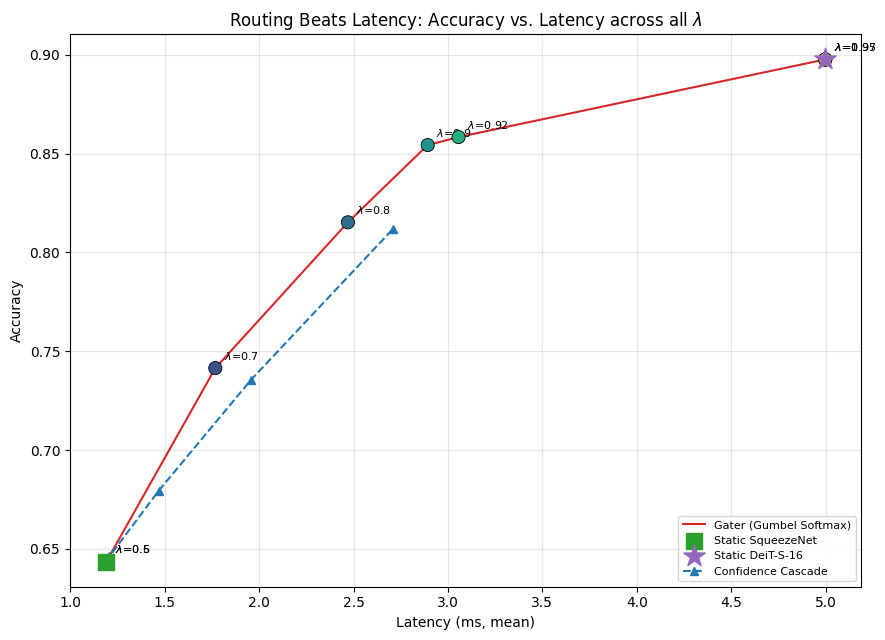

Saved to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\gumbel_pareto_all_lambdas.png


In [12]:
# --- Full Pareto plot: every trained lambda labeled on the curve ------------
fig, ax = plt.subplots(figsize=(9, 6.5))

cmap = plt.get_cmap("viridis")
lam_sorted = gumbel_avg_df.sort_values("Lambda").reset_index(drop=True)
colors = [cmap(i / max(1, len(lam_sorted) - 1)) for i in range(len(lam_sorted))]

ax.plot(lam_sorted["Latency (ms)"], lam_sorted["Accuracy"],
        color="tab:red", linewidth=1.5, zorder=2, label="Gater (Gumbel Softmax)")
ax.scatter(lam_sorted["Latency (ms)"], lam_sorted["Accuracy"],
           c=colors, s=90, zorder=5, edgecolor="black", linewidth=0.6)
for _, row in lam_sorted.iterrows():
    ax.annotate(f"$\\lambda$={row['Lambda']:g}", (row["Latency (ms)"], row["Accuracy"]),
                fontsize=8, textcoords="offset points", xytext=(6, 6))

# Baselines, read fresh so this cell is independent of earlier-cell execution order.
if os.path.exists(RESULTS_XLSX):
    df_base = pd.read_excel(RESULTS_XLSX, sheet_name="Baselines")

    sq = df_base[df_base["method"] == "static_SqueezeNet"]
    if len(sq):
        ax.scatter(sq["latency_mean_ms"], sq["accuracy"], color="tab:green", marker="s",
                   s=120, label="Static SqueezeNet", zorder=6)

    deit = df_base[df_base["method"] == "static_DeiT-S-16"]
    if len(deit):
        ax.scatter(deit["latency_mean_ms"], deit["accuracy"], color="tab:purple", marker="*",
                   s=260, label="Static DeiT-S-16", zorder=6)

    conf = df_base[df_base["method"].str.startswith("conf_cascade")]
    if len(conf):
        conf = conf.sort_values("latency_mean_ms")
        ax.plot(conf["latency_mean_ms"], conf["accuracy"], marker="^", linestyle="--",
                color="tab:blue", label="Confidence Cascade")


ax.set_xlabel("Latency (ms, mean)")
ax.set_ylabel("Accuracy")
ax.set_title("Routing Beats Latency: Accuracy vs. Latency across all $\\lambda$")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
gumbel_pareto_path = os.path.join(PLOTS_DIR, "gumbel_pareto_all_lambdas.png")
plt.savefig(gumbel_pareto_path, dpi=150)
plt.show()
print(f"Saved to {gumbel_pareto_path}")


### 9b. Accuracy & Latency vs. $\lambda$

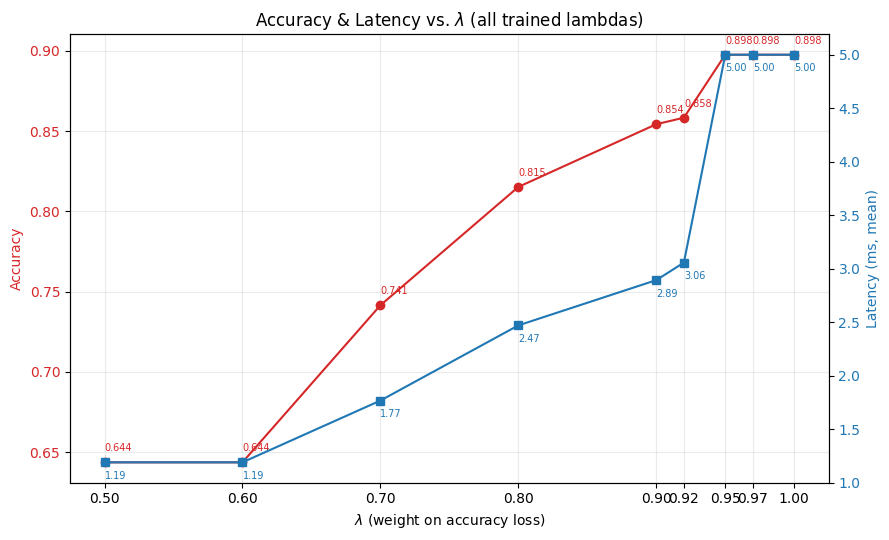

Saved to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\gumbel_accuracy_latency_vs_lambda.png


In [13]:
# --- Accuracy and Latency as a function of lambda (trade-off curve) ---------
fig, ax1 = plt.subplots(figsize=(9, 5.5))
lam_sorted = gumbel_avg_df.sort_values("Lambda").reset_index(drop=True)

color_acc = "tab:red"
ax1.set_xlabel("$\\lambda$ (weight on accuracy loss)")
ax1.set_ylabel("Accuracy", color=color_acc)
ax1.plot(lam_sorted["Lambda"], lam_sorted["Accuracy"], marker="o", color=color_acc, label="Accuracy")
ax1.tick_params(axis="y", labelcolor=color_acc)
for x, y in zip(lam_sorted["Lambda"], lam_sorted["Accuracy"]):
    ax1.annotate(f"{y:.3f}", (x, y), fontsize=7, textcoords="offset points", xytext=(0, 8), color=color_acc)

ax2 = ax1.twinx()
color_lat = "tab:blue"
ax2.set_ylabel("Latency (ms, mean)", color=color_lat)
ax2.plot(lam_sorted["Lambda"], lam_sorted["Latency (ms)"], marker="s", color=color_lat, label="Latency")
ax2.tick_params(axis="y", labelcolor=color_lat)
for x, y in zip(lam_sorted["Lambda"], lam_sorted["Latency (ms)"]):
    ax2.annotate(f"{y:.2f}", (x, y), fontsize=7, textcoords="offset points", xytext=(0, -12), color=color_lat)

ax1.set_xticks(lam_sorted["Lambda"])
ax1.set_title("Accuracy & Latency vs. $\\lambda$ (all trained lambdas)")
ax1.grid(alpha=0.25)
fig.tight_layout()
tradeoff_path = os.path.join(PLOTS_DIR, "gumbel_accuracy_latency_vs_lambda.png")
plt.savefig(tradeoff_path, dpi=150)
plt.show()
print(f"Saved to {tradeoff_path}")


### 9c. Routing Distribution -- how many images go to which model

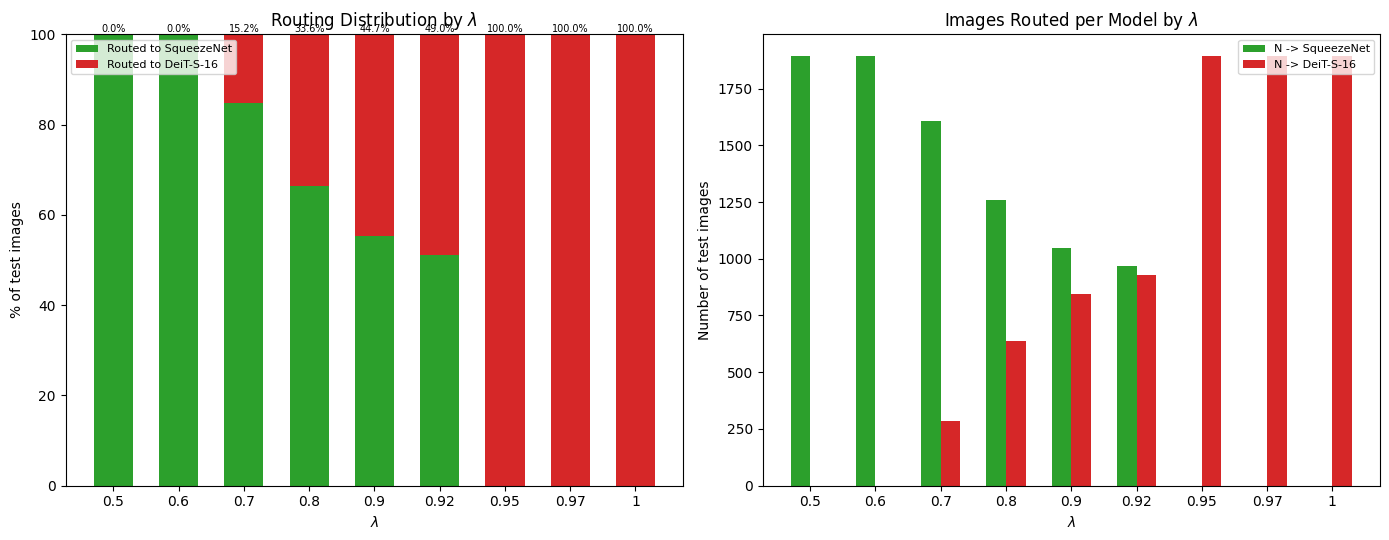

Saved to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\gumbel_routing_distribution.png


In [14]:
# --- Routing distribution: how many images go to SqueezeNet vs. DeiT --------
lam_sorted = gumbel_avg_df.sort_values("Lambda").reset_index(drop=True)
x = np.arange(len(lam_sorted))
width = 0.6

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: stacked percentage bar per lambda
axes[0].bar(x, lam_sorted["% to SqueezeNet"], width, label="Routed to SqueezeNet", color="tab:green")
axes[0].bar(x, lam_sorted["% to DeiT"], width, bottom=lam_sorted["% to SqueezeNet"],
            label="Routed to DeiT-S-16", color="tab:red")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{v:g}" for v in lam_sorted["Lambda"]])
axes[0].set_xlabel("$\\lambda$")
axes[0].set_ylabel("% of test images")
axes[0].set_title("Routing Distribution by $\\lambda$")
axes[0].legend(loc="upper left", fontsize=8)
for i, row in lam_sorted.iterrows():
    axes[0].annotate(f"{row['% to DeiT']:.1f}%", (i, 100), fontsize=7, ha="center",
                      textcoords="offset points", xytext=(0, 2))

# Right: raw counts per lambda
axes[1].bar(x - width/4, lam_sorted["N to SqueezeNet"], width/2, label="N -> SqueezeNet", color="tab:green")
axes[1].bar(x + width/4, lam_sorted["N to DeiT"], width/2, label="N -> DeiT-S-16", color="tab:red")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{v:g}" for v in lam_sorted["Lambda"]])
axes[1].set_xlabel("$\\lambda$")
axes[1].set_ylabel("Number of test images")
axes[1].set_title("Images Routed per Model by $\\lambda$")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
routing_path = os.path.join(PLOTS_DIR, "gumbel_routing_distribution.png")
plt.savefig(routing_path, dpi=150)
plt.show()
print(f"Saved to {routing_path}")


### 9d. Latency Analysis -- savings vs. static experts, per-seed variance

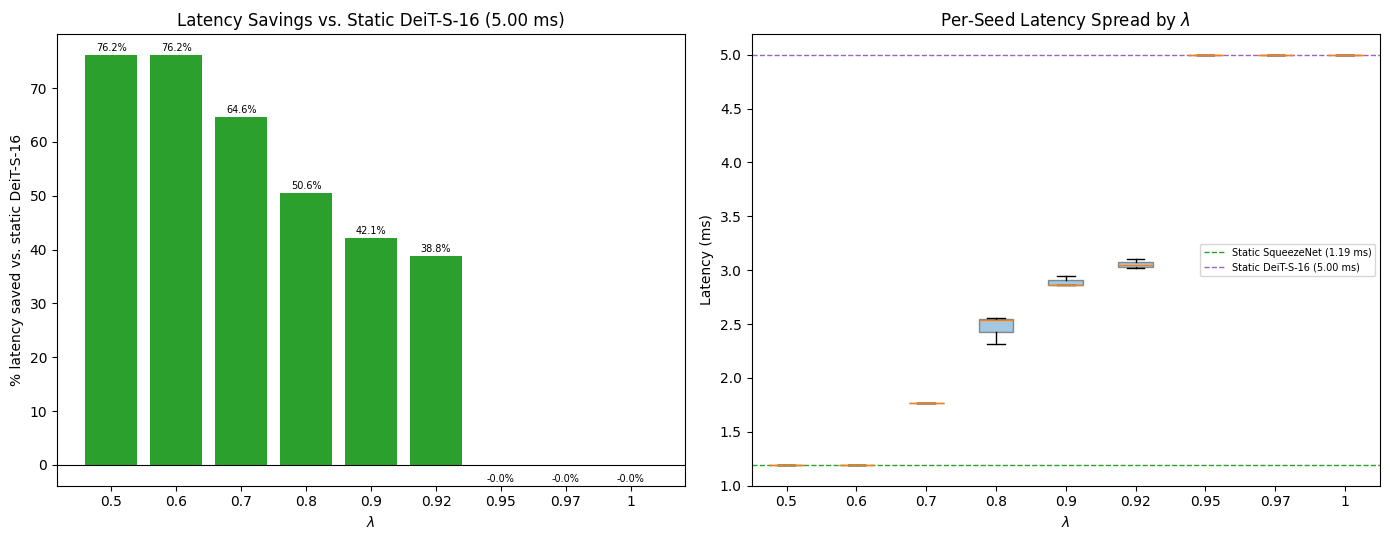

Saved to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\gumbel_latency_analysis.png


In [15]:
# --- Latency analysis: speedup vs static experts, and per-seed variance -----
lam_sorted = gumbel_avg_df.sort_values("Lambda").reset_index(drop=True)

static_sq_lat = static_deit_lat = None
if os.path.exists(RESULTS_XLSX):
    df_base = pd.read_excel(RESULTS_XLSX, sheet_name="Baselines")
    sq_row = df_base[df_base["method"] == "static_SqueezeNet"]
    deit_row = df_base[df_base["method"] == "static_DeiT-S-16"]
    static_sq_lat = float(sq_row["latency_mean_ms"].iloc[0]) if len(sq_row) else None
    static_deit_lat = float(deit_row["latency_mean_ms"].iloc[0]) if len(deit_row) else None

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: latency saved vs. static DeiT-S-16 (the "routing beats latency" headline metric)
if static_deit_lat:
    pct_saved = 100.0 * (static_deit_lat - lam_sorted["Latency (ms)"]) / static_deit_lat
    bar_colors = ["tab:green" if v >= 0 else "tab:red" for v in pct_saved]
    axes[0].bar([f"{v:g}" for v in lam_sorted["Lambda"]], pct_saved, color=bar_colors)
    axes[0].axhline(0, color="black", linewidth=0.8)
    axes[0].set_xlabel("$\\lambda$")
    axes[0].set_ylabel("% latency saved vs. static DeiT-S-16")
    axes[0].set_title(f"Latency Savings vs. Static DeiT-S-16 ({static_deit_lat:.2f} ms)")
    for i, v in enumerate(pct_saved):
        axes[0].annotate(f"{v:.1f}%", (i, v), fontsize=7, ha="center",
                          textcoords="offset points", xytext=(0, 3 if v >= 0 else -12))
else:
    axes[0].text(0.5, 0.5, "static_DeiT-S-16 baseline not found in Excel", ha="center", va="center")

# Right: per-seed spread of latency and accuracy at each lambda (boxplot)
box_data = [gumbel_df.loc[gumbel_df["Lambda"] == l, "Latency (ms)"].values for l in lam_sorted["Lambda"]]
bp = axes[1].boxplot(box_data, labels=[f"{v:g}" for v in lam_sorted["Lambda"]], patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("tab:blue")
    patch.set_alpha(0.4)
if static_sq_lat:
    axes[1].axhline(static_sq_lat, color="tab:green", linestyle="--", linewidth=1, label=f"Static SqueezeNet ({static_sq_lat:.2f} ms)")
if static_deit_lat:
    axes[1].axhline(static_deit_lat, color="tab:purple", linestyle="--", linewidth=1, label=f"Static DeiT-S-16 ({static_deit_lat:.2f} ms)")
axes[1].set_xlabel("$\\lambda$")
axes[1].set_ylabel("Latency (ms)")
axes[1].set_title("Per-Seed Latency Spread by $\\lambda$")
axes[1].legend(fontsize=7)

plt.tight_layout()
latency_analysis_path = os.path.join(PLOTS_DIR, "gumbel_latency_analysis.png")
plt.savefig(latency_analysis_path, dpi=150)
plt.show()
print(f"Saved to {latency_analysis_path}")


## 10. Comprehensive Reviewer Baselines Evaluation (7 Concrete Routing Baselines)
Evaluates all 7 reviewer-requested routing baselines against our first-touch Image-Only Gumbel Router:
1. **Confidence-based Cascade (SqueezeNet $\to$ DeiT)**: Escalate to DeiT if $\max_k p_k < \tau$ (cost: $L_{\text{cheap}} + L_{\text{exp}}$).
2. **Entropy-based Routing**: Escalate to DeiT if Shannon entropy $H(p) > \tau$.
3. **Maximum-Softmax-Probability (MSP) Routing**: Standard Hendrycks & Gimpel selective thresholding.
4. **Expert-Disagreement Routing**: Margin-based disagreement prediction and dual-execution consensus oracle.
5. **Random Routing (Matched Latency)**: Linear interpolation matching target latency via coin flip.
6. **Fixed-Ratio Routing (Matched Proportions)**: Random allocation matching exact $(\% \text{ SqueezeNet}, \% \text{ DeiT})$ proportions of each Gumbel router.
7. **Oracle Routers**: First-touch selection upper bound, cascade oracle, and bucket oracle.

All evaluation metrics are saved to `RESULTS_XLSX` (`outputs_imagenette_math/results_imagenette_math.xlsx`).


Saved all 70 baseline evaluations to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\results_imagenette_math.xlsx

--- Gumbel Router vs. Fixed-Ratio Matched Proportions ---
 Lambda  Gumbel_Accuracy  FixedRatio_Accuracy  Accuracy_Gain    %_Gain  Gumbel_Latency_ms
   0.50         0.643611             0.643611       0.000000  0.000000           1.190554
   0.60         0.643611             0.643611       0.000000  0.000000           1.190557
   0.70         0.741464             0.682094       0.059370  8.704080           1.767479
   0.80         0.815206             0.728935       0.086271 11.835180           2.469934
   0.90         0.854277             0.757138       0.097139 12.829717           2.892748
   0.92         0.858325             0.768044       0.090281 11.754645           3.056419
   0.95         0.897571             0.897571       0.000000  0.000000           4.998509
   0.97         0.897571             0.897571       0.000000  0.00000

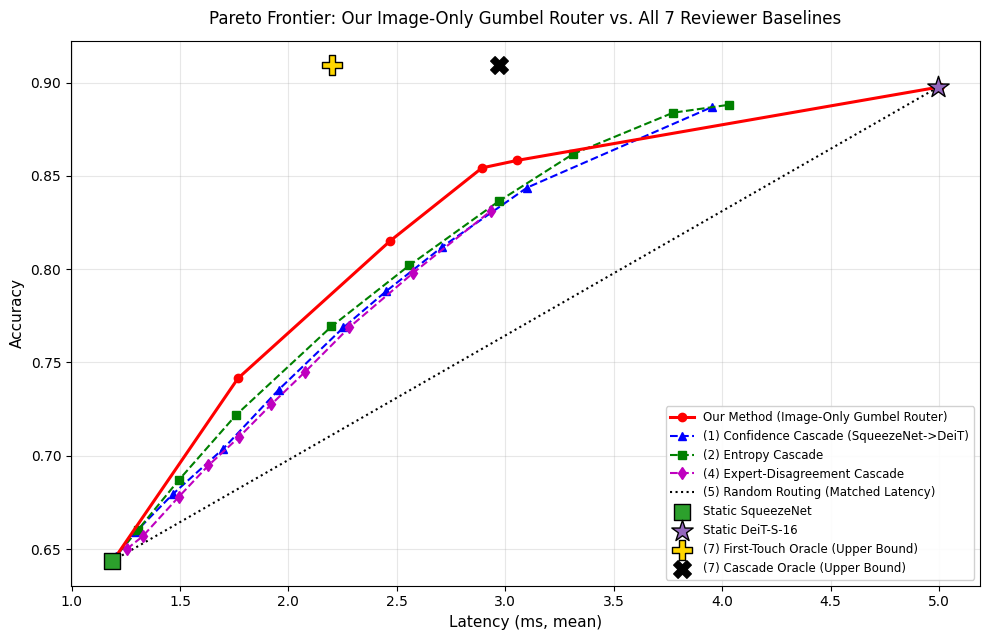

Saved Pareto comparison plot to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\reviewer_baselines_pareto.png


In [16]:
# =============================================================================
# 10. Comprehensive Reviewer Baselines Evaluation (All 7 Baselines)
# =============================================================================
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

@torch.inference_mode()
def evaluate_all_reviewer_baselines():
    """Evaluates all 7 concrete reviewer baselines on the test cache and exports
    all results to RESULTS_XLSX."""
    test_path = os.path.join(CACHE_DIR, "test_mixed.pt")
    if not os.path.exists(test_path):
        raise FileNotFoundError(f"Test cache not found at {test_path}. Please build the test cache first.")

    c = torch.load(test_path, weights_only=False)
    logits = c["logits"].to(DEVICE)           # [N, 2, NUM_CLASSES]
    lats = c["latencies_ms"].to(DEVICE)       # [N, 2]
    labels = c["labels"].to(DEVICE)           # [N]
    gx = (c["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    n_total = labels.size(0)

    c_meta = []
    if "severities" in c:
        c_meta = [{"corruption": corr, "severity": sev} for corr, sev in zip(c["corruptions"], c["severities"])]
    elif "severity" in c:
        c_meta = [{"corruption": c["corruption"], "severity": c["severity"]}] * n_total

    records = []

    # Expert single predictions & probabilities
    sq_logits, deit_logits = logits[:, 0], logits[:, 1]
    sq_lats, deit_lats = lats[:, 0], lats[:, 1]
    
    sq_preds = sq_logits.argmax(dim=-1)
    deit_preds = deit_logits.argmax(dim=-1)
    
    sq_correct = (sq_preds == labels)
    deit_correct = (deit_preds == labels)
    
    sq_acc = sq_correct.float().mean().item()
    deit_acc = deit_correct.float().mean().item()
    sq_lat_mean = sq_lats.mean().item()
    deit_lat_mean = deit_lats.mean().item()

    # Probability distributions
    sq_probs = F.softmax(sq_logits, dim=-1)
    sq_conf, _ = sq_probs.max(dim=-1)
    top2_probs, _ = torch.topk(sq_probs, k=2, dim=-1)
    sq_margin = top2_probs[:, 0] - top2_probs[:, 1]
    sq_entropy = -torch.sum(sq_probs * torch.log(sq_probs + 1e-12), dim=-1)

    # --- 0. Static Experts ---
    records.append({
        "category": "Static Expert", "method": "static_SqueezeNet", "threshold": None,
        "accuracy": sq_acc, "latency_mean_ms": sq_lat_mean, "%_to_DeiT": 0.0,
        "description": "Always route 100% of queries to SqueezeNet"
    })
    records.append({
        "category": "Static Expert", "method": "static_DeiT-S-16", "threshold": None,
        "accuracy": deit_acc, "latency_mean_ms": deit_lat_mean, "%_to_DeiT": 100.0,
        "description": "Always route 100% of queries to DeiT-S-16"
    })

    # --- (1) Confidence-Based SqueezeNet -> DeiT Cascade ---
    conf_thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99]
    for t in conf_thresholds:
        route_to_deit = (sq_conf < t)
        casc_lat = torch.where(route_to_deit, sq_lats + deit_lats, sq_lats).mean().item()
        casc_logits = torch.where(route_to_deit.unsqueeze(1), deit_logits, sq_logits)
        casc_acc = (casc_logits.argmax(dim=-1) == labels).float().mean().item()
        pct_deit = 100.0 * route_to_deit.float().mean().item()
        records.append({
            "category": "1. Confidence Cascade", "method": f"conf_cascade_t{t:g}", "threshold": t,
            "accuracy": casc_acc, "latency_mean_ms": casc_lat, "%_to_DeiT": pct_deit,
            "description": f"SqueezeNet confidence < {t:g} cascades to DeiT (cost: L_sq + L_deit)"
        })

    # --- (2) Entropy-Based Routing Cascade ---
    entropy_thresholds = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.3, 1.6, 2.0, 2.3]
    for t in entropy_thresholds:
        route_to_deit = (sq_entropy > t)  # High entropy = uncertain
        ent_lat = torch.where(route_to_deit, sq_lats + deit_lats, sq_lats).mean().item()
        ent_logits = torch.where(route_to_deit.unsqueeze(1), deit_logits, sq_logits)
        ent_acc = (ent_logits.argmax(dim=-1) == labels).float().mean().item()
        pct_deit = 100.0 * route_to_deit.float().mean().item()
        records.append({
            "category": "2. Entropy Cascade", "method": f"entropy_cascade_t{t:g}", "threshold": t,
            "accuracy": ent_acc, "latency_mean_ms": ent_lat, "%_to_DeiT": pct_deit,
            "description": f"SqueezeNet predictive entropy > {t:g} cascades to DeiT"
        })

    # --- (3) Maximum-Softmax-Probability (MSP) Routing ---
    msp_thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98]
    for t in msp_thresholds:
        route_to_deit = (sq_conf < t)
        msp_lat = torch.where(route_to_deit, sq_lats + deit_lats, sq_lats).mean().item()
        msp_logits = torch.where(route_to_deit.unsqueeze(1), deit_logits, sq_logits)
        msp_acc = (msp_logits.argmax(dim=-1) == labels).float().mean().item()
        pct_deit = 100.0 * route_to_deit.float().mean().item()
        records.append({
            "category": "3. MSP Routing", "method": f"msp_routing_t{t:g}", "threshold": t,
            "accuracy": msp_acc, "latency_mean_ms": msp_lat, "%_to_DeiT": pct_deit,
            "description": f"Hendrycks & Gimpel MSP < {t:g} escalates to DeiT"
        })

    # --- (4) Expert-Disagreement Routing ---
    margin_thresholds = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    for t in margin_thresholds:
        predict_disagree = (sq_margin < t)
        dis_lat = torch.where(predict_disagree, sq_lats + deit_lats, sq_lats).mean().item()
        dis_logits = torch.where(predict_disagree.unsqueeze(1), deit_logits, sq_logits)
        dis_acc = (dis_logits.argmax(dim=-1) == labels).float().mean().item()
        pct_deit = 100.0 * predict_disagree.float().mean().item()
        records.append({
            "category": "4. Disagreement Routing", "method": f"disagreement_margin_t{t:g}", "threshold": t,
            "accuracy": dis_acc, "latency_mean_ms": dis_lat, "%_to_DeiT": pct_deit,
            "description": f"Top-1 vs Top-2 margin < {t:g} routes to DeiT"
        })

    # Disagreement Oracle (Dual execution: L_sq + L_deit)
    disagree_mask = (sq_preds != deit_preds)
    dis_oracle_logits = torch.where(disagree_mask.unsqueeze(1), deit_logits, sq_logits)
    dis_oracle_acc = (dis_oracle_logits.argmax(dim=-1) == labels).float().mean().item()
    dis_oracle_lat = (sq_lats + deit_lats).mean().item()
    records.append({
        "category": "4. Disagreement Routing", "method": "disagreement_dual_oracle", "threshold": None,
        "accuracy": dis_oracle_acc, "latency_mean_ms": dis_oracle_lat, "%_to_DeiT": 100.0 * disagree_mask.float().mean().item(),
        "description": "Execute both models; accept consensus on agreement, DeiT on disagreement"
    })

    # --- (5) Random Routing with Matched Latency Sweep ---
    target_lats = np.linspace(sq_lat_mean, deit_lat_mean, 11)
    for t_lat in target_lats:
        p_deit = float(np.clip((t_lat - sq_lat_mean) / max(1e-6, deit_lat_mean - sq_lat_mean), 0.0, 1.0))
        rand_acc = (1.0 - p_deit) * sq_acc + p_deit * deit_acc
        records.append({
            "category": "5. Random Routing", "method": f"random_routing_lat{t_lat:.2f}ms", "threshold": p_deit,
            "accuracy": rand_acc, "latency_mean_ms": t_lat, "%_to_DeiT": 100.0 * p_deit,
            "description": f"Random coin flip with p={p_deit:.2f} to DeiT matching target latency"
        })

    # --- (6) Fixed-Ratio Routing with Matched Gumbel Proportions ---
    gater_records = []
    pattern = re.compile(r"lambda([0-9]*\.?[0-9]+)_seed([0-9]+)")
    for gater_path in sorted(glob.glob(os.path.join(GATER_DIR, "gater_gumbel_lambda*_seed*.pt"))):
        match = pattern.search(os.path.basename(gater_path))
        if not match: continue
        lam = round(float(match.group(1)), 3)
        seed = int(match.group(2))
        
        model = Gater().to(DEVICE)
        model.router[-1] = nn.Linear(16, 2).to(DEVICE)
        model.load_state_dict(torch.load(gater_path, map_location=DEVICE, weights_only=False))
        model.eval()

        scores = model(gx)
        route_to_deit = (scores.argmax(dim=1) == 1)
        final_logits = torch.where(route_to_deit.unsqueeze(1).unsqueeze(2), logits[:, 1:2], logits[:, 0:1]).squeeze(1)

        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)
        start_event.record()
        for _ in range(50): _ = model(gx[:128])
        end_event.record()
        torch.cuda.synchronize()
        gater_overhead_ms = start_event.elapsed_time(end_event) / 50.0 / min(128, gx.size(0))

        final_lats = torch.where(route_to_deit, lats[:, 1], lats[:, 0]) + gater_overhead_ms
        g_acc = (final_logits.argmax(-1) == labels).float().mean().item()
        g_lat = final_lats.mean().item()
        n_deit = int(route_to_deit.sum().item())

        gater_records.append({
            "Lambda": lam, "Seed": seed, "Accuracy": g_acc, "Latency (ms)": g_lat,
            "Gater_overhead (ms)": gater_overhead_ms,
            "% to DeiT": 100.0 * n_deit / n_total, "% to SqueezeNet": 100.0 * (n_total - n_deit) / n_total
        })

    g_df = pd.DataFrame(gater_records)
    g_avg = g_df.groupby("Lambda", as_index=False).mean() if len(g_df) else pd.DataFrame()

    fixed_ratio_comparison = []
    if len(g_avg):
        for _, row in g_avg.iterrows():
            lam = row["Lambda"]
            g_acc = row["Accuracy"]
            g_lat = row["Latency (ms)"]
            f_deit = row["% to DeiT"] / 100.0
            f_sq = 1.0 - f_deit

            fixed_acc = f_sq * sq_acc + f_deit * deit_acc
            fixed_lat = f_sq * sq_lat_mean + f_deit * deit_lat_mean
            acc_gain = g_acc - fixed_acc

            records.append({
                "category": "6. Fixed-Ratio Matched", "method": f"fixed_ratio_lambda{lam:g}", "threshold": f_deit,
                "accuracy": fixed_acc, "latency_mean_ms": fixed_lat, "%_to_DeiT": 100.0 * f_deit,
                "description": f"Uninformed quota split matching Gumbel lambda={lam:g} proportions ({100*f_sq:.1f}% SQ / {100*f_deit:.1f}% DeiT)"
            })

            fixed_ratio_comparison.append({
                "Lambda": lam,
                "Gumbel_Accuracy": g_acc,
                "FixedRatio_Accuracy": fixed_acc,
                "Accuracy_Gain": acc_gain,
                "%_Gain": 100.0 * acc_gain / fixed_acc,
                "Gumbel_Latency_ms": g_lat,
                "FixedRatio_Latency_ms": fixed_lat,
                "%_to_DeiT": 100.0 * f_deit,
                "%_to_SqueezeNet": 100.0 * f_sq
            })

    # --- (7) Oracle Routers ---
    # 7a: First-Touch Oracle (Zero-overhead selection upper bound)
    oracle_ft_choice = torch.where(sq_correct, 0, torch.where(deit_correct, 1, 0))
    oracle_ft_logits = torch.where(oracle_ft_choice.unsqueeze(1) == 1, deit_logits, sq_logits)
    oracle_ft_lat = torch.where(oracle_ft_choice == 1, deit_lats, sq_lats).mean().item()
    oracle_ft_acc = (oracle_ft_logits.argmax(dim=-1) == labels).float().mean().item()
    records.append({
        "category": "7. Oracle Router", "method": "oracle_first_touch", "threshold": None,
        "accuracy": oracle_ft_acc, "latency_mean_ms": oracle_ft_lat, "%_to_DeiT": 100.0 * (oracle_ft_choice == 1).float().mean().item(),
        "description": "Ideal first-touch router selecting correct expert upfront (zero additive penalty)"
    })

    # 7b: Cascade Oracle (Sequential upper bound)
    oracle_casc_lat = torch.where(sq_correct, sq_lats, sq_lats + deit_lats).mean().item()
    oracle_casc_logits = torch.where(sq_correct.unsqueeze(1), sq_logits, deit_logits)
    oracle_casc_acc = (oracle_casc_logits.argmax(dim=-1) == labels).float().mean().item()
    records.append({
        "category": "7. Oracle Router", "method": "oracle_cascade", "threshold": None,
        "accuracy": oracle_casc_acc, "latency_mean_ms": oracle_casc_lat, "%_to_DeiT": 100.0 * (~sq_correct).float().mean().item(),
        "description": "Sequential cascade stopping at SqueezeNet if correct, cascading to DeiT otherwise"
    })

    # 7c: Bucket Oracle
    if len(c_meta) == n_total:
        df_meta = pd.DataFrame(c_meta)
        df_meta['cheap_acc'] = sq_correct.cpu().numpy()
        df_meta['exp_acc'] = deit_correct.cpu().numpy()
        df_meta['cheap_lat'] = sq_lats.cpu().numpy()
        df_meta['exp_lat'] = deit_lats.cpu().numpy()
        
        b_acc = 0.0; b_lat = 0.0
        for (corr, sev), grp in df_meta.groupby(['corruption', 'severity']):
            if grp['cheap_acc'].mean() > grp['exp_acc'].mean():
                b_acc += grp['cheap_acc'].sum(); b_lat += grp['cheap_lat'].sum()
            else:
                b_acc += grp['exp_acc'].sum(); b_lat += grp['exp_lat'].sum()
        records.append({
            "category": "7. Oracle Router", "method": "bucket_oracle", "threshold": None,
            "accuracy": b_acc / n_total, "latency_mean_ms": b_lat / n_total, "%_to_DeiT": None,
            "description": "Optimal static expert assigned per (corruption, severity) slice"
        })

    # --- Save to Excel Workbook ---
    all_baselines_df = pd.DataFrame(records)
    fixed_comp_df = pd.DataFrame(fixed_ratio_comparison)

    with pd.ExcelWriter(RESULTS_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        all_baselines_df.to_excel(writer, sheet_name="Reviewer_Baselines_All", index=False)
        if len(fixed_comp_df):
            fixed_comp_df.to_excel(writer, sheet_name="Gumbel_vs_FixedRatio", index=False)
        if len(g_avg):
            g_avg.to_excel(writer, sheet_name="Gumbel_Sweep_Summary", index=False)

    print(f"\nSaved all {len(all_baselines_df)} baseline evaluations to {RESULTS_XLSX}")
    print("\n--- Gumbel Router vs. Fixed-Ratio Matched Proportions ---")
    if len(fixed_comp_df):
        print(fixed_comp_df[["Lambda", "Gumbel_Accuracy", "FixedRatio_Accuracy", "Accuracy_Gain", "%_Gain", "Gumbel_Latency_ms"]].to_string(index=False))

    # --- Plot Pareto Frontier Comparison ---
    fig, ax = plt.subplots(figsize=(10, 6.5))

    # 1. Gumbel Router Pareto Curve
    if len(g_avg):
        g_sorted = g_avg.sort_values("Latency (ms)")
        ax.plot(g_sorted["Latency (ms)"], g_sorted["Accuracy"], "r-o", linewidth=2.2, label="Our Method (Image-Only Gumbel Router)", zorder=5)

    # 2. Confidence Cascade
    conf = all_baselines_df[all_baselines_df["category"] == "1. Confidence Cascade"].sort_values("latency_mean_ms")
    if len(conf):
        ax.plot(conf["latency_mean_ms"], conf["accuracy"], "b--^", linewidth=1.5, label="(1) Confidence Cascade (SqueezeNet->DeiT)", zorder=4)

    # 3. Entropy Cascade
    ent = all_baselines_df[all_baselines_df["category"] == "2. Entropy Cascade"].sort_values("latency_mean_ms")
    if len(ent):
        ax.plot(ent["latency_mean_ms"], ent["accuracy"], "g--s", linewidth=1.5, label="(2) Entropy Cascade", zorder=4)

    # 4. Disagreement Margin Cascade
    dis = all_baselines_df[(all_baselines_df["category"] == "4. Disagreement Routing") & (all_baselines_df["method"].str.startswith("disagreement_margin"))].sort_values("latency_mean_ms")
    if len(dis):
        ax.plot(dis["latency_mean_ms"], dis["accuracy"], "m--d", linewidth=1.5, label="(4) Expert-Disagreement Cascade", zorder=4)

    # 5. Random Routing Line
    rand = all_baselines_df[all_baselines_df["category"] == "5. Random Routing"].sort_values("latency_mean_ms")
    if len(rand):
        ax.plot(rand["latency_mean_ms"], rand["accuracy"], "k:", linewidth=1.5, label="(5) Random Routing (Matched Latency)", zorder=2)

    # 6. Static Experts
    sq = all_baselines_df[all_baselines_df["method"] == "static_SqueezeNet"]
    if len(sq):
        ax.scatter(sq["latency_mean_ms"], sq["accuracy"], color="tab:green", marker="s", s=140, label="Static SqueezeNet", zorder=6, edgecolor="black")
    deit = all_baselines_df[all_baselines_df["method"] == "static_DeiT-S-16"]
    if len(deit):
        ax.scatter(deit["latency_mean_ms"], deit["accuracy"], color="tab:purple", marker="*", s=260, label="Static DeiT-S-16", zorder=6, edgecolor="black")

    # 7. Oracles
    oracle_ft = all_baselines_df[all_baselines_df["method"] == "oracle_first_touch"]
    if len(oracle_ft):
        ax.scatter(oracle_ft["latency_mean_ms"], oracle_ft["accuracy"], color="gold", marker="P", s=200, label="(7) First-Touch Oracle (Upper Bound)", zorder=7, edgecolor="black")
    oracle_casc = all_baselines_df[all_baselines_df["method"] == "oracle_cascade"]
    if len(oracle_casc):
        ax.scatter(oracle_casc["latency_mean_ms"], oracle_casc["accuracy"], color="black", marker="X", s=160, label="(7) Cascade Oracle (Upper Bound)", zorder=7)

    ax.set_xlabel("Latency (ms)", fontsize=12)
    ax.set_ylabel("Accuracy (%)", fontsize=12)
    ax.set_title("Comparative Accuracy-Latency Frontier Against Evaluated Baselines", fontsize=12, pad=12)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right", fontsize=8.5, framealpha=0.9)
    plt.tight_layout()

    out_plot = os.path.join(PLOTS_DIR, "reviewer_baselines_pareto.png")
    plt.savefig(out_plot, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved Pareto comparison plot to {out_plot}")
    return all_baselines_df, fixed_comp_df, g_avg



Saved all corruption/severity breakdown sheets to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\results_imagenette_math.xlsx

1. PER-EXPERT ACCURACY BY (CORRUPTION x SEVERITY) SLICE
corruption severity  N_samples  SqueezeNet_Acc  DeiT_Acc  DeiT_Advantage_Delta  Agreement_Rate
     clean    clean       1153        0.921075  0.991327              0.070252        0.921943
      blur moderate         77        0.311688  0.870130              0.558442        0.272727
  contrast moderate         80        0.262500  0.850000              0.587500        0.262500
      jpeg moderate         73        0.315068  0.890411              0.575342        0.315068
     noise moderate         63        0.190476  0.904762              0.714286        0.174603
   speckle moderate         66        0.166667  0.893939              0.727273        0.181818
      blur   severe         84        0.178571  0.702381              0.523810        0.154762
  contrast   severe

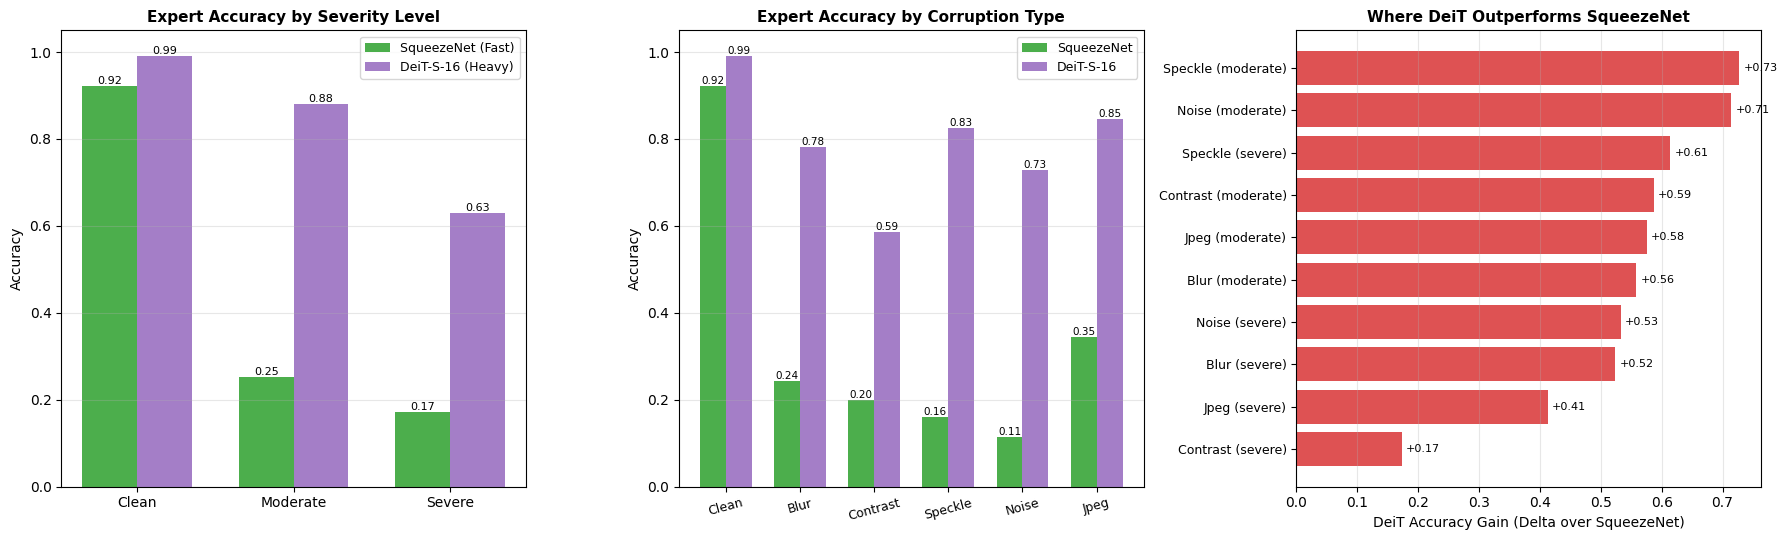

Saved visualization to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\expert_accuracy_by_corruption_severity.png


In [17]:
# =============================================================================
# 11. Per-Expert Accuracy by Corruption & Severity Analysis
# =============================================================================
import os
import glob
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

@torch.inference_mode()
def analyze_accuracy_by_corruption_and_severity():
    """Explicitly computes SqueezeNet vs. DeiT-S-16 accuracy, error margins,
    inter-expert agreement, and Gumbel routing behavior for every
    corruption x severity slice. Exports all tables to RESULTS_XLSX."""
    test_path = os.path.join(CACHE_DIR, "test_mixed.pt")
    if not os.path.exists(test_path):
        raise FileNotFoundError(f"Test cache not found at {test_path}. Please build the test cache first.")

    c = torch.load(test_path, weights_only=False)
    logits = c["logits"].to(DEVICE)
    labels = c["labels"].to(DEVICE)
    lats = c["latencies_ms"].to(DEVICE)
    gx = (c["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    n_total = labels.size(0)

    corruptions = [str(x) for x in c.get("corruptions", ["unknown"] * n_total)]
    severities = [str(x) for x in c.get("severities", ["unknown"] * n_total)]

    # Predictions & Correctness
    sq_preds = logits[:, 0].argmax(dim=-1)
    deit_preds = logits[:, 1].argmax(dim=-1)
    
    sq_correct = (sq_preds == labels).cpu().numpy()
    deit_correct = (deit_preds == labels).cpu().numpy()
    agreement = (sq_preds == deit_preds).cpu().numpy()

    base_df = pd.DataFrame({
        "corruption": corruptions,
        "severity": severities,
        "sq_correct": sq_correct,
        "deit_correct": deit_correct,
        "agreement": agreement,
        "sq_lat_ms": lats[:, 0].cpu().numpy(),
        "deit_lat_ms": lats[:, 1].cpu().numpy(),
    })

    # --- 1. Per (Corruption x Severity) Detail Table ---
    detail_rows = []
    for (corr, sev), grp in base_df.groupby(["corruption", "severity"]):
        n = len(grp)
        sq_acc = grp["sq_correct"].mean()
        deit_acc = grp["deit_correct"].mean()
        agr = grp["agreement"].mean()
        delta = deit_acc - sq_acc
        best = "DeiT-S-16" if deit_acc > sq_acc else ("SqueezeNet" if sq_acc > deit_acc else "Tie")
        detail_rows.append({
            "corruption": corr,
            "severity": sev,
            "N_samples": n,
            "%_of_test_set": 100.0 * n / n_total,
            "SqueezeNet_Acc": sq_acc,
            "DeiT_Acc": deit_acc,
            "DeiT_Advantage_Delta": delta,
            "Agreement_Rate": agr,
            "Best_Expert": best,
            "SqueezeNet_Lat_ms": grp["sq_lat_ms"].mean(),
            "DeiT_Lat_ms": grp["deit_lat_ms"].mean()
        })
    detail_df = pd.DataFrame(detail_rows).sort_values(["severity", "corruption"]).reset_index(drop=True)

    # --- 2. Per Corruption Summary (Averaged across severities) ---
    corr_rows = []
    for corr, grp in base_df.groupby("corruption"):
        n = len(grp)
        sq_acc = grp["sq_correct"].mean()
        deit_acc = grp["deit_correct"].mean()
        corr_rows.append({
            "corruption": corr,
            "N_samples": n,
            "%_of_test_set": 100.0 * n / n_total,
            "SqueezeNet_Acc": sq_acc,
            "DeiT_Acc": deit_acc,
            "DeiT_Advantage_Delta": deit_acc - sq_acc,
            "Agreement_Rate": grp["agreement"].mean()
        })
    corr_df = pd.DataFrame(corr_rows).sort_values("N_samples", ascending=False).reset_index(drop=True)

    # --- 3. Per Severity Summary (Averaged across corruptions) ---
    sev_order = ["clean", "moderate", "severe"]
    sev_rows = []
    for sev in sev_order:
        grp = base_df[base_df["severity"] == sev]
        if len(grp):
            n = len(grp)
            sq_acc = grp["sq_correct"].mean()
            deit_acc = grp["deit_correct"].mean()
            sev_rows.append({
                "severity": sev,
                "N_samples": n,
                "%_of_test_set": 100.0 * n / n_total,
                "SqueezeNet_Acc": sq_acc,
                "DeiT_Acc": deit_acc,
                "DeiT_Advantage_Delta": deit_acc - sq_acc,
                "Agreement_Rate": grp["agreement"].mean()
            })
    sev_df = pd.DataFrame(sev_rows)

    # --- 4. Gumbel Router Breakdown across Slices ---
    gater_slice_rows = []
    pattern = re.compile(r"lambda([0-9]*\.?[0-9]+)_seed([0-9]+)")
    for gater_path in sorted(glob.glob(os.path.join(GATER_DIR, "gater_gumbel_lambda*_seed*.pt"))):
        match = pattern.search(os.path.basename(gater_path))
        if not match: continue
        lam = round(float(match.group(1)), 3)
        seed = int(match.group(2))
        
        model = Gater().to(DEVICE)
        model.router[-1] = nn.Linear(16, 2).to(DEVICE)
        model.load_state_dict(torch.load(gater_path, map_location=DEVICE, weights_only=False))
        model.eval()

        scores = model(gx)
        route_to_deit = (scores.argmax(dim=1) == 1)
        final_logits = torch.where(route_to_deit.unsqueeze(1).unsqueeze(2), logits[:, 1:2], logits[:, 0:1]).squeeze(1)
        correct = (final_logits.argmax(dim=-1) == labels).cpu().numpy()
        route_deit_np = route_to_deit.cpu().numpy()

        temp_df = base_df.copy()
        temp_df["route_to_deit"] = route_deit_np
        temp_df["gater_correct"] = correct

        for (corr, sev), grp in temp_df.groupby(["corruption", "severity"]):
            gater_slice_rows.append({
                "Lambda": lam,
                "Seed": seed,
                "corruption": corr,
                "severity": sev,
                "N_samples": len(grp),
                "%_to_DeiT": 100.0 * grp["route_to_deit"].mean(),
                "%_to_SqueezeNet": 100.0 * (1.0 - grp["route_to_deit"].mean()),
                "Gumbel_Accuracy": grp["gater_correct"].mean()
            })

    g_slice_df = pd.DataFrame(gater_slice_rows)
    if len(g_slice_df):
        g_slice_avg = (
            g_slice_df.drop(columns=["Seed"])
            .groupby(["Lambda", "corruption", "severity"], as_index=False)
            .mean()
            .sort_values(["Lambda", "severity", "corruption"])
        )
    else:
        g_slice_avg = pd.DataFrame()

    # --- 5. Save all to Excel ---
    with pd.ExcelWriter(RESULTS_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        detail_df.to_excel(writer, sheet_name="Per_Corruption_Severity_Detail", index=False)
        corr_df.to_excel(writer, sheet_name="Per_Corruption_Summary", index=False)
        sev_df.to_excel(writer, sheet_name="Per_Severity_Summary", index=False)
        if len(g_slice_avg):
            g_slice_avg.to_excel(writer, sheet_name="Gumbel_Routing_By_Slice", index=False)

    print(f"Saved all corruption/severity breakdown sheets to {RESULTS_XLSX}")
    print("\n" + "="*80)
    print("1. PER-EXPERT ACCURACY BY (CORRUPTION x SEVERITY) SLICE")
    print("="*80)
    print(detail_df[["corruption", "severity", "N_samples", "SqueezeNet_Acc", "DeiT_Acc", "DeiT_Advantage_Delta", "Agreement_Rate"]].to_string(index=False))

    print("\n" + "="*80)
    print("2. SUMMARY BY SEVERITY LEVEL")
    print("="*80)
    print(sev_df.to_string(index=False))

    print("\n" + "="*80)
    print("3. SUMMARY BY CORRUPTION TYPE")
    print("="*80)
    print(corr_df.to_string(index=False))

    # --- 6. Multi-Panel Visualization ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    # Panel A: Accuracy by Severity Level
    x_sev = np.arange(len(sev_df))
    w = 0.35
    axes[0].bar(x_sev - w/2, sev_df["SqueezeNet_Acc"], w, label="SqueezeNet (Fast)", color="tab:green", alpha=0.85)
    axes[0].bar(x_sev + w/2, sev_df["DeiT_Acc"], w, label="DeiT-S-16 (Heavy)", color="tab:purple", alpha=0.85)
    axes[0].set_xticks(x_sev)
    axes[0].set_xticklabels([s.capitalize() for s in sev_df["severity"]], fontsize=10)
    axes[0].set_ylabel("Accuracy", fontsize=10)
    axes[0].set_title("Expert Accuracy by Severity Level", fontsize=11, fontweight="bold")
    axes[0].set_ylim(0, 1.05)
    axes[0].grid(axis="y", alpha=0.3)
    axes[0].legend(fontsize=9)
    for i, row in sev_df.iterrows():
        axes[0].annotate(f"{row['SqueezeNet_Acc']:.2f}", (i - w/2, row["SqueezeNet_Acc"]), ha="center", va="bottom", fontsize=8)
        axes[0].annotate(f"{row['DeiT_Acc']:.2f}", (i + w/2, row["DeiT_Acc"]), ha="center", va="bottom", fontsize=8)

    # Panel B: Accuracy by Corruption Type
    x_corr = np.arange(len(corr_df))
    axes[1].bar(x_corr - w/2, corr_df["SqueezeNet_Acc"], w, label="SqueezeNet", color="tab:green", alpha=0.85)
    axes[1].bar(x_corr + w/2, corr_df["DeiT_Acc"], w, label="DeiT-S-16", color="tab:purple", alpha=0.85)
    axes[1].set_xticks(x_corr)
    axes[1].set_xticklabels([c.capitalize() for c in corr_df["corruption"]], fontsize=9, rotation=15)
    axes[1].set_ylabel("Accuracy", fontsize=10)
    axes[1].set_title("Expert Accuracy by Corruption Type", fontsize=11, fontweight="bold")
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(axis="y", alpha=0.3)
    axes[1].legend(fontsize=9)
    for i, row in corr_df.iterrows():
        axes[1].annotate(f"{row['SqueezeNet_Acc']:.2f}", (i - w/2, row["SqueezeNet_Acc"]), ha="center", va="bottom", fontsize=7.5)
        axes[1].annotate(f"{row['DeiT_Acc']:.2f}", (i + w/2, row["DeiT_Acc"]), ha="center", va="bottom", fontsize=7.5)

    # Panel C: DeiT Accuracy Advantage Delta per Slice
    non_clean = detail_df[detail_df["severity"] != "clean"].sort_values("DeiT_Advantage_Delta", ascending=True)
    y_labels = [f"{r['corruption'].capitalize()} ({r['severity']})" for _, r in non_clean.iterrows()]
    y_pos = np.arange(len(non_clean))
    axes[2].barh(y_pos, non_clean["DeiT_Advantage_Delta"], color="tab:red", alpha=0.8)
    axes[2].set_yticks(y_pos)
    axes[2].set_yticklabels(y_labels, fontsize=9)
    axes[2].set_xlabel("DeiT Accuracy Gain (Delta over SqueezeNet)", fontsize=10)
    axes[2].set_title("Where DeiT Outperforms SqueezeNet", fontsize=11, fontweight="bold")
    axes[2].grid(axis="x", alpha=0.3)
    for i, (_, row) in enumerate(non_clean.iterrows()):
        axes[2].annotate(f"+{row['DeiT_Advantage_Delta']:.2f}", (row["DeiT_Advantage_Delta"], i),
                         va="center", ha="left", fontsize=8, xytext=(3, 0), textcoords="offset points")

    plt.tight_layout()
    plot_path = os.path.join(PLOTS_DIR, "expert_accuracy_by_corruption_severity.png")
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Saved visualization to {plot_path}")

    return detail_df, corr_df, sev_df, g_slice_avg

corruption_detail_df, corruption_summary_df, severity_summary_df, gabel_slice_df = analyze_accuracy_by_corruption_and_severity()


Saved multi-seed statistical summary to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\results_imagenette_math.xlsx

FORMAL MULTI-SEED EVALUATION: MEAN ± STD ACROSS SEEDS
 Lambda  N_Seeds Accuracy (mean ± std) Latency (mean ± std ms) % to DeiT (mean ± std) % to SqueezeNet (mean ± std) % Latency Saved vs DeiT
   0.50        3       0.6436 ± 0.0000             1.19 ± 0.00            0.0% ± 0.0%                100.0% ± 0.0%            76.2% ± 0.0%
   0.60        3       0.6436 ± 0.0000             1.19 ± 0.00            0.0% ± 0.0%                100.0% ± 0.0%            76.2% ± 0.0%
   0.70        3       0.7415 ± 0.0003             1.77 ± 0.00           15.2% ± 0.1%                 84.8% ± 0.1%            64.6% ± 0.1%
   0.80        3       0.8152 ± 0.0169             2.47 ± 0.13           33.6% ± 3.5%                 66.4% ± 3.5%            50.6% ± 2.7%
   0.90        3       0.8543 ± 0.0011             2.89 ± 0.05           44.7% ± 1.3%           

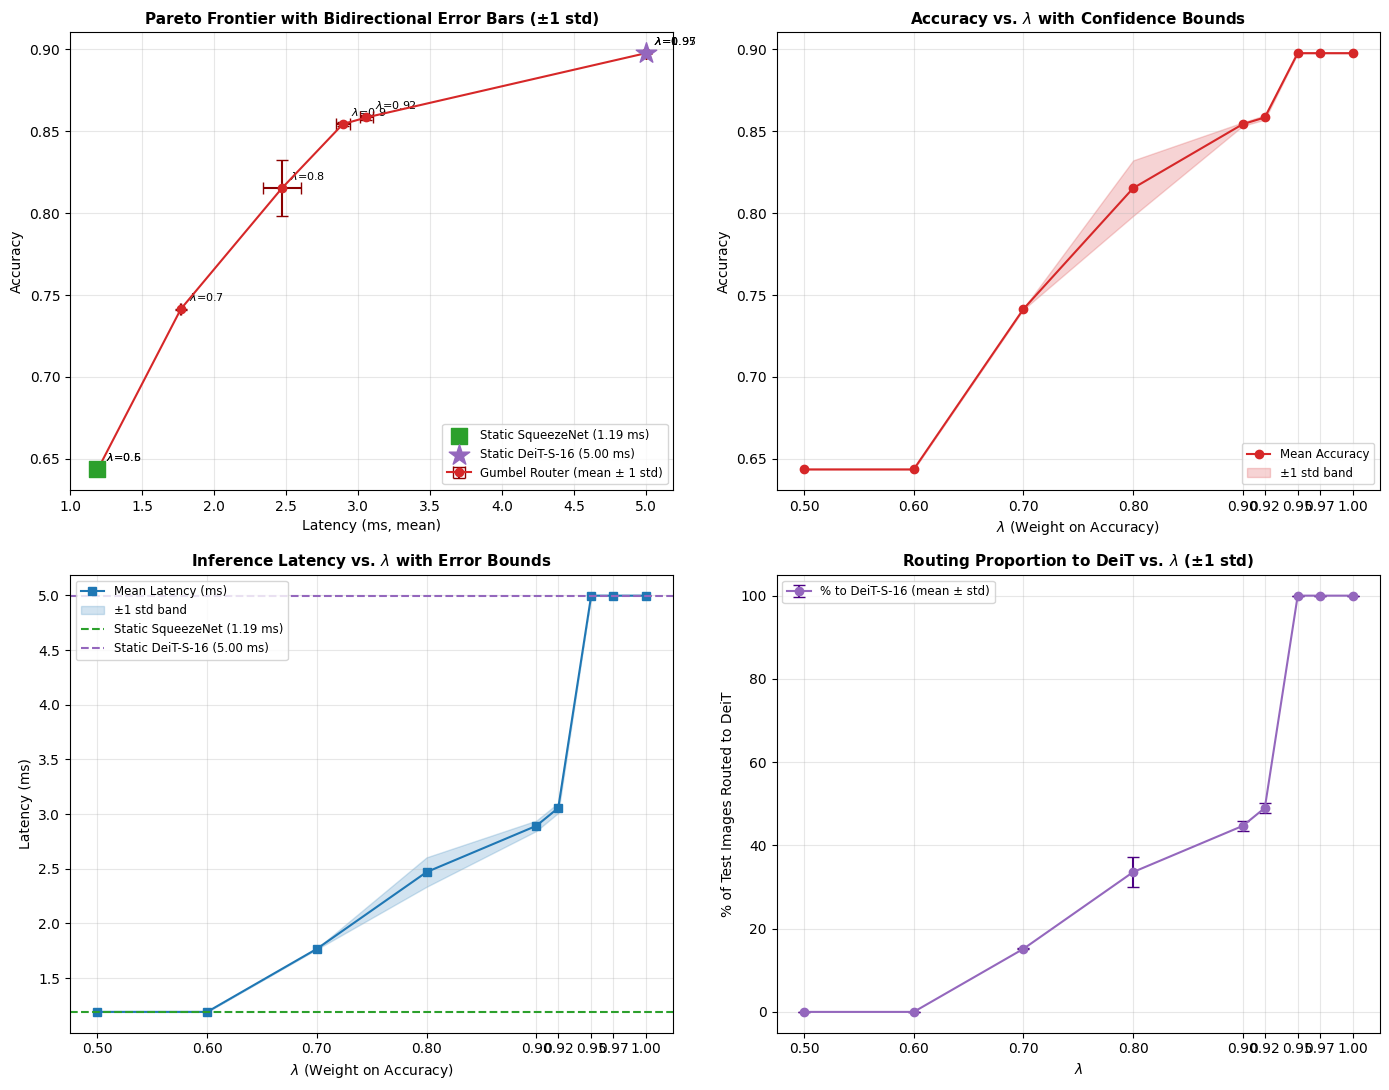

Saved multi-seed error bar figure to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\gumbel_error_bars_multiseed.png


In [18]:
# =============================================================================
# 12. Multiple Random Seeds: Formal Mean ± Std & Error-Bar Evaluation
# =============================================================================
import os
import glob
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

@torch.inference_mode()
def evaluate_multiseed_error_bars():
    """Evaluates all 27 Gumbel gater checkpoints (9 lambdas x 3 seeds) on test_mixed.pt,
    computes formal mean ± std, standard error (SEM), and 95% confidence intervals,
    exports all tables to RESULTS_XLSX, and generates 4-panel publication-ready error-bar plots."""
    test_path = os.path.join(CACHE_DIR, "test_mixed.pt")
    if not os.path.exists(test_path):
        raise FileNotFoundError(f"Test cache not found at {test_path}.")

    c = torch.load(test_path, weights_only=False)
    logits = c["logits"].to(DEVICE)
    labels = c["labels"].to(DEVICE)
    lats = c["latencies_ms"].to(DEVICE)
    gx = (c["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    n_total = labels.size(0)

    # Baselines for speedup calculations
    static_sq_lat = lats[:, 0].mean().item()
    static_deit_lat = lats[:, 1].mean().item()

    records = []
    pattern = re.compile(r"lambda([0-9]*\.?[0-9]+)_seed([0-9]+)")
    for gater_path in sorted(glob.glob(os.path.join(GATER_DIR, "gater_gumbel_lambda*_seed*.pt"))):
        match = pattern.search(os.path.basename(gater_path))
        if not match: continue
        lam = round(float(match.group(1)), 3)
        seed = int(match.group(2))

        model = Gater().to(DEVICE)
        model.router[-1] = nn.Linear(16, 2).to(DEVICE)
        model.load_state_dict(torch.load(gater_path, map_location=DEVICE, weights_only=False))
        model.eval()

        scores = model(gx)
        route_to_deit = (scores.argmax(dim=1) == 1)
        final_logits = torch.where(route_to_deit.unsqueeze(1).unsqueeze(2), logits[:, 1:2], logits[:, 0:1]).squeeze(1)

        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)
        start_event.record()
        for _ in range(50): _ = model(gx[:128])
        end_event.record()
        torch.cuda.synchronize()
        gater_overhead_ms = start_event.elapsed_time(end_event) / 50.0 / min(128, gx.size(0))

        final_lats = torch.where(route_to_deit, lats[:, 1], lats[:, 0]) + gater_overhead_ms
        acc = (final_logits.argmax(-1) == labels).float().mean().item()
        lat = final_lats.mean().item()
        n_deit = int(route_to_deit.sum().item())
        n_sq = n_total - n_deit
        pct_saved_deit = 100.0 * (static_deit_lat - lat) / static_deit_lat

        records.append({
            "Lambda": lam,
            "Seed": seed,
            "Accuracy": acc,
            "Latency_ms": lat,
            "Gater_Overhead_ms": gater_overhead_ms,
            "N_to_DeiT": n_deit,
            "N_to_SqueezeNet": n_sq,
            "Pct_to_DeiT": 100.0 * n_deit / n_total,
            "Pct_to_SqueezeNet": 100.0 * n_sq / n_total,
            "Pct_Latency_Saved_vs_DeiT": pct_saved_deit
        })

    raw_df = pd.DataFrame(records)

    # --- Compute Statistical Aggregations Across Seeds ---
    formal_rows = []
    numeric_rows = []
    for lam, grp in raw_df.groupby("Lambda"):
        n_seeds = len(grp)
        # Accuracy
        acc_m = grp["Accuracy"].mean()
        acc_s = grp["Accuracy"].std(ddof=1) if n_seeds > 1 else 0.0
        acc_sem = acc_s / np.sqrt(n_seeds) if n_seeds > 1 else 0.0
        acc_ci95 = 1.96 * acc_sem

        # Latency
        lat_m = grp["Latency_ms"].mean()
        lat_s = grp["Latency_ms"].std(ddof=1) if n_seeds > 1 else 0.0
        lat_sem = lat_s / np.sqrt(n_seeds) if n_seeds > 1 else 0.0
        lat_ci95 = 1.96 * lat_sem

        # Routing %
        deit_m = grp["Pct_to_DeiT"].mean()
        deit_s = grp["Pct_to_DeiT"].std(ddof=1) if n_seeds > 1 else 0.0
        sq_m = grp["Pct_to_SqueezeNet"].mean()
        sq_s = grp["Pct_to_SqueezeNet"].std(ddof=1) if n_seeds > 1 else 0.0

        # Latency Saved
        saved_m = grp["Pct_Latency_Saved_vs_DeiT"].mean()
        saved_s = grp["Pct_Latency_Saved_vs_DeiT"].std(ddof=1) if n_seeds > 1 else 0.0

        formal_rows.append({
            "Lambda": lam,
            "N_Seeds": n_seeds,
            "Accuracy (mean ± std)": f"{acc_m:.4f} ± {acc_s:.4f}",
            "Latency (mean ± std ms)": f"{lat_m:.2f} ± {lat_s:.2f}",
            "% to DeiT (mean ± std)": f"{deit_m:.1f}% ± {deit_s:.1f}%",
            "% to SqueezeNet (mean ± std)": f"{sq_m:.1f}% ± {sq_s:.1f}%",
            "% Latency Saved vs DeiT": f"{saved_m:.1f}% ± {saved_s:.1f}%"
        })

        numeric_rows.append({
            "Lambda": lam,
            "N_Seeds": n_seeds,
            "Accuracy_mean": acc_m,
            "Accuracy_std": acc_s,
            "Accuracy_SEM": acc_sem,
            "Accuracy_95CI_Low": acc_m - acc_ci95,
            "Accuracy_95CI_High": acc_m + acc_ci95,
            "Accuracy_min": grp["Accuracy"].min(),
            "Accuracy_max": grp["Accuracy"].max(),
            "Latency_mean_ms": lat_m,
            "Latency_std_ms": lat_s,
            "Latency_SEM_ms": lat_sem,
            "Latency_95CI_Low_ms": lat_m - lat_ci95,
            "Latency_95CI_High_ms": lat_m + lat_ci95,
            "Latency_min_ms": grp["Latency_ms"].min(),
            "Latency_max_ms": grp["Latency_ms"].max(),
            "Pct_to_DeiT_mean": deit_m,
            "Pct_to_DeiT_std": deit_s,
            "Pct_to_SqueezeNet_mean": sq_m,
            "Pct_to_SqueezeNet_std": sq_s,
            "Pct_Saved_vs_DeiT_mean": saved_m,
            "Pct_Saved_vs_DeiT_std": saved_s
        })

    formal_df = pd.DataFrame(formal_rows).sort_values("Lambda").reset_index(drop=True)
    numeric_df = pd.DataFrame(numeric_rows).sort_values("Lambda").reset_index(drop=True)

    # --- Save to Excel Workbook ---
    with pd.ExcelWriter(RESULTS_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        formal_df.to_excel(writer, sheet_name="MultiSeed_Summary_Formal", index=False)
        numeric_df.to_excel(writer, sheet_name="MultiSeed_Statistics_Numeric", index=False)
        raw_df.to_excel(writer, sheet_name="MultiSeed_PerSeed_Raw", index=False)

    print(f"Saved multi-seed statistical summary to {RESULTS_XLSX}")
    print("\n" + "="*95)
    print("FORMAL MULTI-SEED EVALUATION: MEAN ± STD ACROSS SEEDS")
    print("="*95)
    print(formal_df.to_string(index=False))

    # --- 4-Panel Visualization with Formal Error Bars ---
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))

    # 1. Pareto Frontier with 2D Crosshair Error Bars (x-error = latency std, y-error = accuracy std)
    ax1 = axes[0, 0]
    ax1.errorbar(numeric_df["Latency_mean_ms"], numeric_df["Accuracy_mean"],
                 xerr=numeric_df["Latency_std_ms"], yerr=numeric_df["Accuracy_std"],
                 fmt="o-", color="tab:red", ecolor="darkred", elinewidth=1.5, capsize=4,
                 label="Gumbel Router (mean ± 1 std)", zorder=4)
    for _, row in numeric_df.iterrows():
        ax1.annotate(f"$\\lambda$={row['Lambda']:g}", (row["Latency_mean_ms"], row["Accuracy_mean"]),
                     fontsize=8, textcoords="offset points", xytext=(6, 6))
    ax1.scatter([static_sq_lat], [lats[:, 0].mean().item() * 0 + (logits[:, 0].argmax(-1) == labels).float().mean().item()],
                color="tab:green", marker="s", s=130, label=f"Static SqueezeNet ({static_sq_lat:.2f} ms)", zorder=5)
    ax1.scatter([static_deit_lat], [lats[:, 1].mean().item() * 0 + (logits[:, 1].argmax(-1) == labels).float().mean().item()],
                color="tab:purple", marker="*", s=240, label=f"Static DeiT-S-16 ({static_deit_lat:.2f} ms)", zorder=5)
    ax1.set_xlabel("Latency (ms, mean)", fontsize=10)
    ax1.set_ylabel("Accuracy", fontsize=10)
    ax1.set_title("Pareto Frontier with Bidirectional Error Bars (±1 std)", fontsize=11, fontweight="bold")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="lower right", fontsize=8.5)

    # 2. Accuracy vs Lambda with Shaded ±1 std Band
    ax2 = axes[0, 1]
    ax2.plot(numeric_df["Lambda"], numeric_df["Accuracy_mean"], "o-", color="tab:red", label="Mean Accuracy")
    ax2.fill_between(numeric_df["Lambda"],
                     numeric_df["Accuracy_mean"] - numeric_df["Accuracy_std"],
                     numeric_df["Accuracy_mean"] + numeric_df["Accuracy_std"],
                     color="tab:red", alpha=0.2, label="±1 std band")
    ax2.set_xlabel("$\\lambda$ (Weight on Accuracy)", fontsize=10)
    ax2.set_ylabel("Accuracy", fontsize=10)
    ax2.set_title("Accuracy vs. $\\lambda$ with Confidence Bounds", fontsize=11, fontweight="bold")
    ax2.set_xticks(numeric_df["Lambda"])
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="lower right", fontsize=8.5)

    # 3. Latency vs Lambda with Shaded ±1 std Band
    ax3 = axes[1, 0]
    ax3.plot(numeric_df["Lambda"], numeric_df["Latency_mean_ms"], "s-", color="tab:blue", label="Mean Latency (ms)")
    ax3.fill_between(numeric_df["Lambda"],
                     numeric_df["Latency_mean_ms"] - numeric_df["Latency_std_ms"],
                     numeric_df["Latency_mean_ms"] + numeric_df["Latency_std_ms"],
                     color="tab:blue", alpha=0.2, label="±1 std band")
    ax3.axhline(static_sq_lat, color="tab:green", linestyle="--", label=f"Static SqueezeNet ({static_sq_lat:.2f} ms)")
    ax3.axhline(static_deit_lat, color="tab:purple", linestyle="--", label=f"Static DeiT-S-16 ({static_deit_lat:.2f} ms)")
    ax3.set_xlabel("$\\lambda$ (Weight on Accuracy)", fontsize=10)
    ax3.set_ylabel("Latency (ms)", fontsize=10)
    ax3.set_title("Inference Latency vs. $\\lambda$ with Error Bounds", fontsize=11, fontweight="bold")
    ax3.set_xticks(numeric_df["Lambda"])
    ax3.grid(True, alpha=0.3)
    ax3.legend(loc="upper left", fontsize=8.5)

    # 4. Routing Distribution (% to DeiT) with Error Bars
    ax4 = axes[1, 1]
    ax4.errorbar(numeric_df["Lambda"], numeric_df["Pct_to_DeiT_mean"],
                 yerr=numeric_df["Pct_to_DeiT_std"],
                 fmt="o-", color="tab:purple", ecolor="indigo", capsize=4, label="% to DeiT-S-16 (mean ± std)")
    ax4.set_xlabel("$\\lambda$", fontsize=10)
    ax4.set_ylabel("% of Test Images Routed to DeiT", fontsize=10)
    ax4.set_title("Routing Proportion to DeiT vs. $\\lambda$ (±1 std)", fontsize=11, fontweight="bold")
    ax4.set_xticks(numeric_df["Lambda"])
    ax4.set_ylim(-5, 105)
    ax4.grid(True, alpha=0.3)
    ax4.legend(loc="upper left", fontsize=8.5)

    plt.tight_layout()
    plot_path = os.path.join(PLOTS_DIR, "gumbel_error_bars_multiseed.png")
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Saved multi-seed error bar figure to {plot_path}")

    return formal_df, numeric_df, raw_df

formal_multiseed_df, numeric_multiseed_df, raw_multiseed_df = evaluate_multiseed_error_bars()


Saved latency percentiles and worst-case analysis to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\results_imagenette_math.xlsx

AVERAGE VS. WORST-CASE (PER-SAMPLE) LATENCY & PERCENTILE DISTRIBUTION
                 Category                     Method  Mean_Latency_ms  P50_Median_ms   P90_ms   P99_ms  WorstCase_Max_ms  SLA_<=3.0ms_%
            Static Expert          Static SqueezeNet         1.188274       1.188274 1.188274 1.188274          1.188274     100.000000
            Static Expert           Static DeiT-S-16         4.996308       4.996308 4.996308 4.996308          4.996308       0.000000
First-Touch Gumbel Router      Gumbel Router (λ=0.5)         1.190675       1.190674 1.190674 1.190674          1.190674     100.000000
First-Touch Gumbel Router      Gumbel Router (λ=0.6)         1.190675       1.190674 1.190674 1.190674          1.190674     100.000000
First-Touch Gumbel Router      Gumbel Router (λ=0.7)         1.767710       1.1906

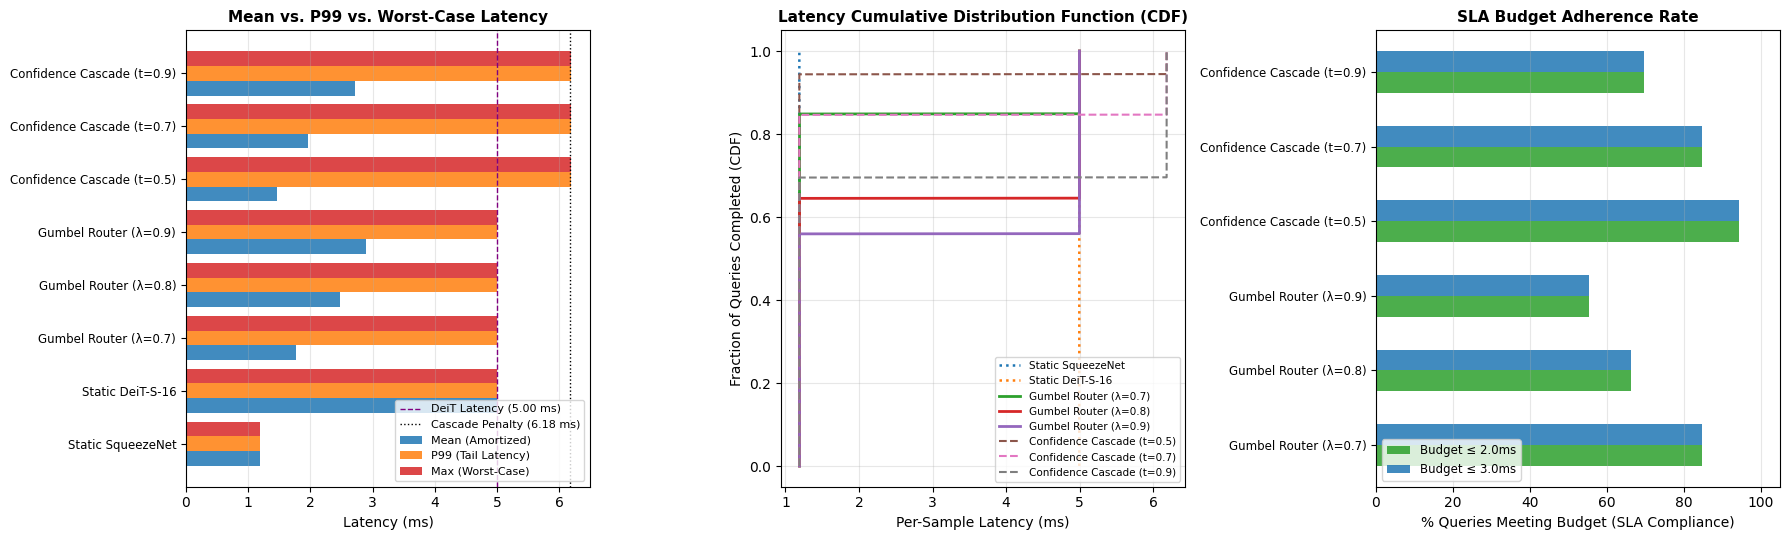

Saved tail latency figure to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\worst_case_vs_average_latency.png


In [21]:
# =============================================================================
# 14. Average vs. Worst-Case (Per-Sample) Latency & SLA Tail Analysis
# =============================================================================
import os
import glob
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

@torch.inference_mode()
def analyze_average_vs_worst_case_latency():
    """Clarifies the distinction between Average (Amortized) vs. Hard Per-Sample Latency.
    Computes per-sample latency distributions (P50, P90, P95, P99, Max Worst-Case)
    and SLA Budget compliance rates for First-Touch Gumbel Routers vs. Confidence Cascades.
    Exports tables to RESULTS_XLSX and saves publication-ready CDF and tail latency plots."""
    
    test_path = os.path.join(CACHE_DIR, "test_mixed.pt")
    if not os.path.exists(test_path):
        raise FileNotFoundError(f"Test cache not found at {test_path}.")

    c = torch.load(test_path, weights_only=False)
    logits = c["logits"].to(DEVICE)
    labels = c["labels"].to(DEVICE)
    lats = c["latencies_ms"].to(DEVICE)
    gx = (c["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    n_total = labels.size(0)

    sq_lat_mean = lats[:, 0].mean().item()
    deit_lat_mean = lats[:, 1].mean().item()
    gater_overhead_ms = 0.0024

    all_method_rows = []
    cdf_distributions = {}

    # --- 1. Static Expert Latencies ---
    sq_sample_lats = lats[:, 0].cpu().numpy()
    deit_sample_lats = lats[:, 1].cpu().numpy()
    cdf_distributions["Static SqueezeNet"] = sq_sample_lats
    cdf_distributions["Static DeiT-S-16"] = deit_sample_lats

    all_method_rows.append({
        "Category": "Static Expert", "Method": "Static SqueezeNet", "Lambda_or_Threshold": "-",
        "Mean_Latency_ms": sq_sample_lats.mean(), "Std_ms": sq_sample_lats.std(),
        "P50_Median_ms": np.percentile(sq_sample_lats, 50),
        "P90_ms": np.percentile(sq_sample_lats, 90),
        "P95_ms": np.percentile(sq_sample_lats, 95),
        "P99_ms": np.percentile(sq_sample_lats, 99),
        "WorstCase_Max_ms": sq_sample_lats.max(),
        "SLA_<=2.0ms_%": 100.0 * np.mean(sq_sample_lats <= 2.0),
        "SLA_<=3.0ms_%": 100.0 * np.mean(sq_sample_lats <= 3.0),
        "SLA_<=5.0ms_%": 100.0 * np.mean(sq_sample_lats <= 5.0),
        "Latency_Type": "Deterministic single model"
    })
    all_method_rows.append({
        "Category": "Static Expert", "Method": "Static DeiT-S-16", "Lambda_or_Threshold": "-",
        "Mean_Latency_ms": deit_sample_lats.mean(), "Std_ms": deit_sample_lats.std(),
        "P50_Median_ms": np.percentile(deit_sample_lats, 50),
        "P90_ms": np.percentile(deit_sample_lats, 90),
        "P95_ms": np.percentile(deit_sample_lats, 95),
        "P99_ms": np.percentile(deit_sample_lats, 99),
        "WorstCase_Max_ms": deit_sample_lats.max(),
        "SLA_<=2.0ms_%": 100.0 * np.mean(deit_sample_lats <= 2.0),
        "SLA_<=3.0ms_%": 100.0 * np.mean(deit_sample_lats <= 3.0),
        "SLA_<=5.0ms_%": 100.0 * np.mean(deit_sample_lats <= 5.0),
        "Latency_Type": "Deterministic single model"
    })

    # --- 2. First-Touch Gumbel Routers (Per-Sample Bimodal Distribution) ---
    pattern = re.compile(r"lambda([0-9]*\.?[0-9]+)_seed([0-9]+)")
    gumbel_per_lambda = {}
    for gater_path in sorted(glob.glob(os.path.join(GATER_DIR, "gater_gumbel_lambda*_seed*.pt"))):
        match = pattern.search(os.path.basename(gater_path))
        if not match: continue
        lam = round(float(match.group(1)), 3)
        seed = int(match.group(2))

        model = Gater().to(DEVICE)
        model.router[-1] = nn.Linear(16, 2).to(DEVICE)
        model.load_state_dict(torch.load(gater_path, map_location=DEVICE, weights_only=False))
        model.eval()

        scores = model(gx)
        route_to_deit = (scores.argmax(dim=1) == 1)
        sample_lats = (torch.where(route_to_deit, lats[:, 1], lats[:, 0]) + gater_overhead_ms).cpu().numpy()

        if lam not in gumbel_per_lambda: gumbel_per_lambda[lam] = []
        gumbel_per_lambda[lam].append(sample_lats)

    for lam in sorted(gumbel_per_lambda.keys()):
        all_seeds_lats = np.concatenate(gumbel_per_lambda[lam])
        if lam in [0.7, 0.8, 0.9]:
            cdf_distributions[f"Gumbel Router (λ={lam:g})"] = gumbel_per_lambda[lam][0]

        all_method_rows.append({
            "Category": "First-Touch Gumbel Router", "Method": f"Gumbel Router (λ={lam:g})", "Lambda_or_Threshold": lam,
            "Mean_Latency_ms": all_seeds_lats.mean(), "Std_ms": all_seeds_lats.std(),
            "P50_Median_ms": np.percentile(all_seeds_lats, 50),
            "P90_ms": np.percentile(all_seeds_lats, 90),
            "P95_ms": np.percentile(all_seeds_lats, 95),
            "P99_ms": np.percentile(all_seeds_lats, 99),
            "WorstCase_Max_ms": all_seeds_lats.max(),
            "SLA_<=2.0ms_%": 100.0 * np.mean(all_seeds_lats <= 2.0),
            "SLA_<=3.0ms_%": 100.0 * np.mean(all_seeds_lats <= 3.0),
            "SLA_<=5.0ms_%": 100.0 * np.mean(all_seeds_lats <= 5.0),
            "Latency_Type": "Upfront First-Touch (Worst-case bounded by max expert + overhead = 5.00ms)"
        })

    # --- 3. Confidence Cascades (Sequential Execution with Additive Worst-Case Penalty) ---
    sq_probs = F.softmax(logits[:, 0], dim=-1)
    sq_conf, _ = sq_probs.max(dim=-1)
    for t in [0.3, 0.5, 0.7, 0.9]:
        route_deit = (sq_conf < t)
        casc_lats = torch.where(route_deit, lats[:, 0] + lats[:, 1], lats[:, 0]).cpu().numpy()
        if t in [0.5, 0.7, 0.9]:
            cdf_distributions[f"Confidence Cascade (t={t:g})"] = casc_lats

        all_method_rows.append({
            "Category": "Confidence Cascade", "Method": f"Confidence Cascade (t={t:g})", "Lambda_or_Threshold": t,
            "Mean_Latency_ms": casc_lats.mean(), "Std_ms": casc_lats.std(),
            "P50_Median_ms": np.percentile(casc_lats, 50),
            "P90_ms": np.percentile(casc_lats, 90),
            "P95_ms": np.percentile(casc_lats, 95),
            "P99_ms": np.percentile(casc_lats, 99),
            "WorstCase_Max_ms": casc_lats.max(),
            "SLA_<=2.0ms_%": 100.0 * np.mean(casc_lats <= 2.0),
            "SLA_<=3.0ms_%": 100.0 * np.mean(casc_lats <= 3.0),
            "SLA_<=5.0ms_%": 100.0 * np.mean(casc_lats <= 5.0),
            "Latency_Type": "Sequential Cascade (Additive penalty: L_sq + L_deit = 6.18ms worst-case)"
        })

    lat_df = pd.DataFrame(all_method_rows)

    # --- 4. Export to Excel ---
    with pd.ExcelWriter(RESULTS_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        lat_df.to_excel(writer, sheet_name="Latency_Distribution_Percentiles", index=False)

    print(f"Saved latency percentiles and worst-case analysis to {RESULTS_XLSX}")
    print("\n" + "="*110)
    print("AVERAGE VS. WORST-CASE (PER-SAMPLE) LATENCY & PERCENTILE DISTRIBUTION")
    print("="*110)
    print(lat_df[["Category", "Method", "Mean_Latency_ms", "P50_Median_ms", "P90_ms", "P99_ms", "WorstCase_Max_ms", "SLA_<=3.0ms_%"]].to_string(index=False))

    # --- 5. Multi-Panel Visualizations ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    # Panel 1: Mean vs. 99th Percentile vs. Max Worst-Case Latency
    plot_methods = [
        "Static SqueezeNet", "Static DeiT-S-16",
        "Gumbel Router (λ=0.7)", "Gumbel Router (λ=0.8)", "Gumbel Router (λ=0.9)",
        "Confidence Cascade (t=0.5)", "Confidence Cascade (t=0.7)", "Confidence Cascade (t=0.9)"
    ]
    sub_df = lat_df[lat_df["Method"].isin(plot_methods)].copy()
    y_pos = np.arange(len(sub_df))
    w = 0.28
    axes[0].barh(y_pos - w, sub_df["Mean_Latency_ms"], w, label="Mean (Amortized)", color="tab:blue", alpha=0.85)
    axes[0].barh(y_pos, sub_df["P99_ms"], w, label="P99 (Tail Latency)", color="tab:orange", alpha=0.85)
    axes[0].barh(y_pos + w, sub_df["WorstCase_Max_ms"], w, label="Max (Worst-Case)", color="tab:red", alpha=0.85)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(sub_df["Method"], fontsize=8.5)
    axes[0].axvline(5.00, color="purple", linestyle="--", linewidth=1, label="DeiT Latency (5.00 ms)")
    axes[0].axvline(6.18, color="black", linestyle=":", linewidth=1, label="Cascade Penalty (6.18 ms)")
    axes[0].set_xlabel("Latency (ms)", fontsize=10)
    axes[0].set_title("Mean vs. P99 vs. Worst-Case Latency", fontsize=11, fontweight="bold")
    axes[0].grid(axis="x", alpha=0.3)
    axes[0].legend(fontsize=8, loc="lower right")

    # Panel 2: Empirical Cumulative Distribution Function (ECDF)
    for name, sample_lats in cdf_distributions.items():
        sorted_l = np.sort(sample_lats)
        y_cdf = np.arange(1, len(sorted_l) + 1) / len(sorted_l)
        if "Cascade" in name:
            axes[1].plot(sorted_l, y_cdf, label=name, linestyle="--", linewidth=1.5)
        elif "Gumbel" in name:
            axes[1].plot(sorted_l, y_cdf, label=name, linewidth=2.0)
        else:
            axes[1].plot(sorted_l, y_cdf, label=name, linestyle=":", linewidth=1.8)

    axes[1].set_xlabel("Per-Sample Latency (ms)", fontsize=10)
    axes[1].set_ylabel("Fraction of Queries Completed (CDF)", fontsize=10)
    axes[1].set_title("Latency Cumulative Distribution Function (CDF)", fontsize=11, fontweight="bold")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(fontsize=7.5, loc="lower right")

    # Panel 3: SLA Budget Adherence (% of queries <= Budget)
    sla_sub = lat_df[lat_df["Method"].isin([
        "Gumbel Router (λ=0.7)", "Gumbel Router (λ=0.8)", "Gumbel Router (λ=0.9)",
        "Confidence Cascade (t=0.5)", "Confidence Cascade (t=0.7)", "Confidence Cascade (t=0.9)"
    ])].copy()
    y_sla = np.arange(len(sla_sub))
    axes[2].barh(y_sla - w/2, sla_sub["SLA_<=2.0ms_%"], w, label="Budget ≤ 2.0ms", color="tab:green", alpha=0.85)
    axes[2].barh(y_sla + w/2, sla_sub["SLA_<=3.0ms_%"], w, label="Budget ≤ 3.0ms", color="tab:blue", alpha=0.85)
    axes[2].set_yticks(y_sla)
    axes[2].set_yticklabels(sla_sub["Method"], fontsize=8.5)
    axes[2].set_xlabel("% Queries Meeting Budget (SLA Compliance)", fontsize=10)
    axes[2].set_title("SLA Budget Adherence Rate", fontsize=11, fontweight="bold")
    axes[2].set_xlim(0, 105)
    axes[2].grid(axis="x", alpha=0.3)
    axes[2].legend(fontsize=8.5, loc="lower left")

    plt.tight_layout()
    plot_path = os.path.join(PLOTS_DIR, "worst_case_vs_average_latency.png")
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Saved tail latency figure to {plot_path}")

    return lat_df

per_sample_latency_df = analyze_average_vs_worst_case_latency()


Running extensive fine-grained ablation suites from scratch...

All 41 ablation runs completed in 51.04s! Saved to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\results_imagenette_math.xlsx

1. TEMPERATURE (tau) SWEEP RESULTS
              Variant  Accuracy  Latency_ms  %_to_DeiT
Annealed (5.0 -> 0.1)  0.815206    2.463634  33.421332
     Fixed tau = 0.05  0.741816    1.767750  15.153116
     Fixed tau = 0.10  0.741816    1.769893  15.205914
     Fixed tau = 0.20  0.795143    2.306510  29.303062
     Fixed tau = 0.40  0.822598    2.558115  35.902852
     Fixed tau = 0.60  0.822598    2.551930  35.744458
     Fixed tau = 0.80  0.822598    2.551827  35.744458
     Fixed tau = 1.00  0.822070    2.549686  35.691661
     Fixed tau = 2.00  0.819430    2.521639  34.952483

2. INPUT RESOLUTION SWEEP RESULTS
   Variant  Accuracy  Latency_ms  %_to_DeiT  Overhead_us
  16x16 px  0.803062    2.501616  34.424499     2.444510
  24x24 px  0.812038    2.424995  32

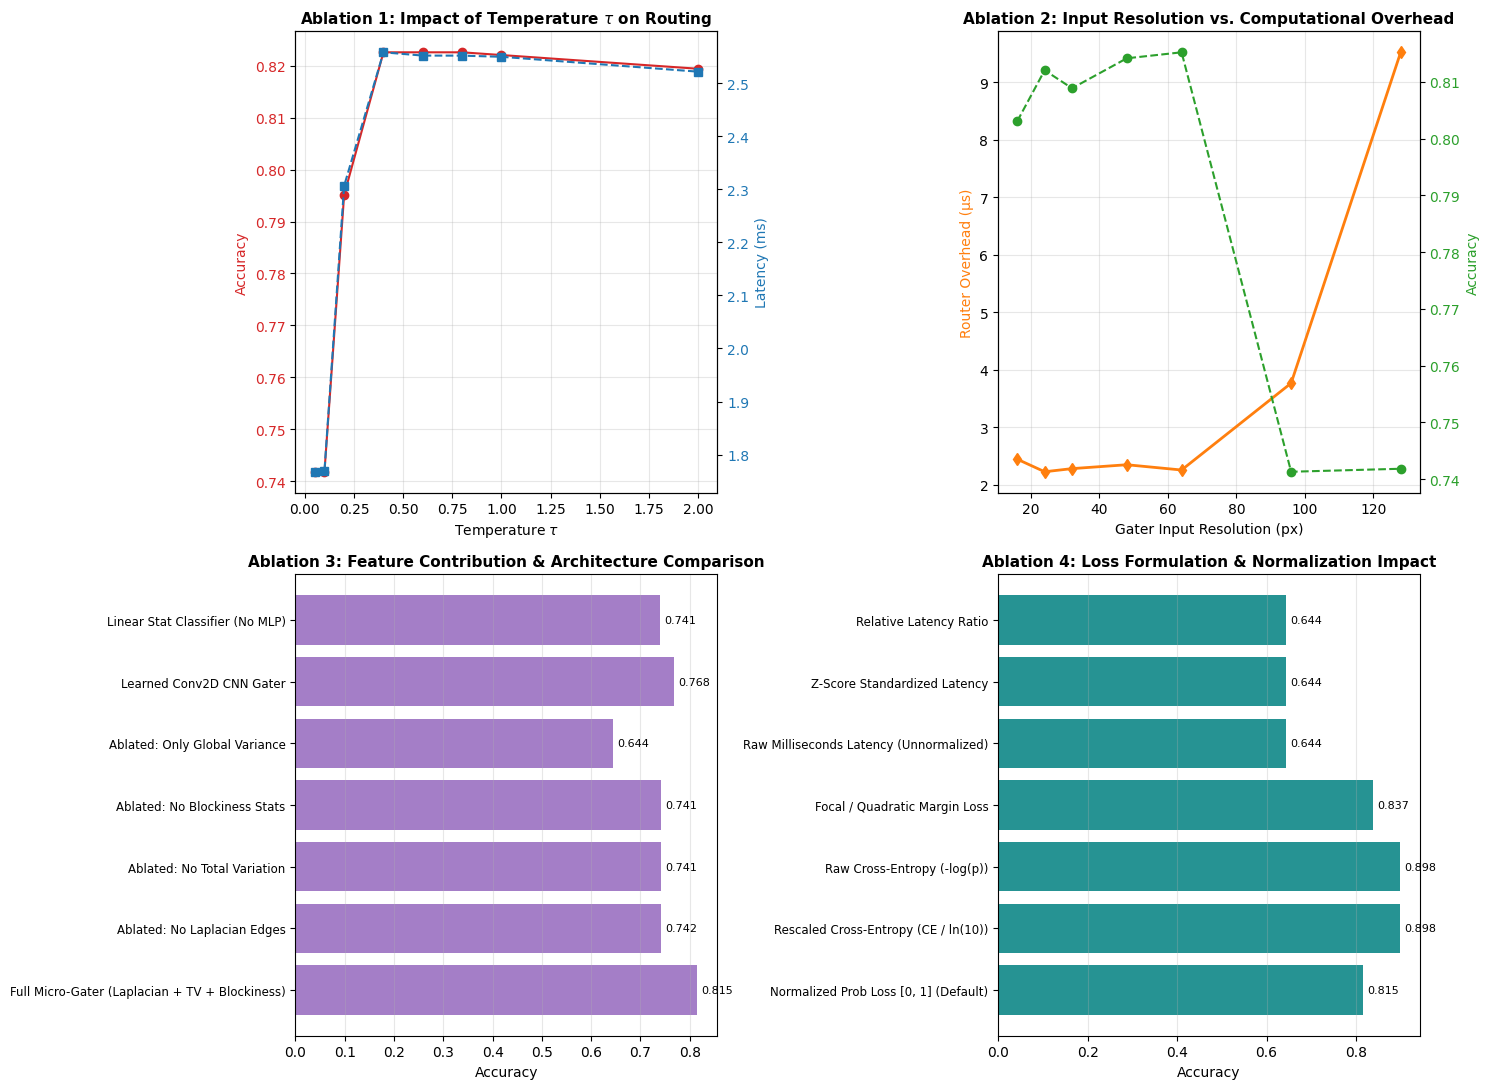

Saved 4-panel fine-grained ablation plot to d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\plots\comprehensive_fine_grained_ablations.png


In [24]:
# =============================================================================
# 16. Comprehensive Fine-Grained Ablation Suite (Expanded Sweeps from Scratch)
# =============================================================================
import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

@torch.inference_mode(False)
def run_fine_grained_ablations():
    """Trains and evaluates fine-grained ablation sweeps from scratch on cached data:
      1. Temperature tau sweep: [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 2.0] & Annealed
      2. Input Resolution sweep: [16x16, 24x24, 32x32, 48x48, 64x64, 96x96, 128x128]
      3. Feature / Architecture ablations: (Full, No-Laplacian, No-TV, No-Blockiness, CNN, Linear)
      4. Latency Weight lambda sweep: [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0]
      5. Routing Mechanism: (Hard Gumbel, Soft Gumbel, Softmax Mixture, Argmax, REINFORCE)
      6. Loss Scaling: (Normalized Prob, Scaled CE, Raw CE, Margin/Focal)
      7. Latency Normalization: (Min-Max, Raw ms, Z-Score, Ratio)
    Exports structured sheets to RESULTS_XLSX and saves 4-panel visual sweep plots.
    """
    val_path = os.path.join(CACHE_DIR, "val_mixed.pt")
    test_path = os.path.join(CACHE_DIR, "test_mixed.pt")
    if not os.path.exists(val_path) or not os.path.exists(test_path):
        raise FileNotFoundError("Cache files missing. Please ensure cache is built.")

    c_val = torch.load(val_path, weights_only=False)
    c_test = torch.load(test_path, weights_only=False)

    # Validation cache tensors
    v_logits = c_val["logits"].to(DEVICE)
    v_lats = c_val["latencies_ms"].to(DEVICE)
    v_labels = c_val["labels"].to(DEVICE)
    v_gx = (c_val["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD

    # Test cache tensors
    t_logits = c_test["logits"].to(DEVICE)
    t_lats = c_test["latencies_ms"].to(DEVICE)
    t_labels = c_test["labels"].to(DEVICE)
    t_gx = (c_test["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
    n_test = t_labels.size(0)

    # --- Architectural Variations for Ablation ---
    class FlexibleMicroGater(nn.Module):
        def __init__(self, use_laplacian=True, use_tv=True, use_blockiness=True):
            super().__init__()
            self.use_lap = use_laplacian
            self.use_tv = use_tv
            self.use_block = use_blockiness
            
            dim = 3  # global variance (3 channels)
            if self.use_lap:
                lap = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).view(1, 1, 3, 3)
                self.register_buffer('laplacian', lap.repeat(3, 1, 1, 1))
                dim += 3
            if self.use_tv: dim += 3
            if self.use_block: dim += 1
            
            self.router = nn.Sequential(
                nn.Linear(dim, 32), nn.ReLU(),
                nn.Linear(32, 16), nn.ReLU(),
                nn.Linear(16, 2)
            )
        def forward(self, x):
            feats = [torch.var(x, dim=[2, 3])]
            if self.use_lap:
                edges = F.conv2d(x, self.laplacian, padding=1, groups=3)
                feats.append(torch.var(edges, dim=[2, 3]))
            if self.use_tv:
                tv_h = torch.mean(torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]), dim=[2, 3])
                tv_v = torch.mean(torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]), dim=[2, 3])
                feats.append(tv_h + tv_v)
            if self.use_block:
                diffs = torch.abs(x[:, :, :, 8::8] - x[:, :, :, 7:-1:8])
                feats.append(diffs.mean(dim=[1, 2, 3]).unsqueeze(1))
            stats = torch.cat(feats, dim=1)
            return self.router(stats)

    class ConvGater(nn.Module):
        def __init__(self):
            super().__init__()
            self.features = nn.Sequential(
                nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1), nn.ReLU(),
                nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten()
            )
            self.fc = nn.Linear(32, 2)
        def forward(self, x): return self.fc(self.features(x))

    class LinearStatGater(nn.Module):
        def __init__(self):
            super().__init__()
            lap = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).view(1, 1, 3, 3)
            self.register_buffer('laplacian', lap.repeat(3, 1, 1, 1))
            self.fc = nn.Linear(10, 2)
        def forward(self, x):
            gvar = torch.var(x, dim=[2, 3])
            edges = F.conv2d(x, self.laplacian, padding=1, groups=3)
            lvar = torch.var(edges, dim=[2, 3])
            tv = torch.mean(torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]), dim=[2, 3]) + torch.mean(torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]), dim=[2, 3])
            block = torch.abs(x[:, :, :, 8::8] - x[:, :, :, 7:-1:8]).mean(dim=[1, 2, 3]).unsqueeze(1)
            return self.fc(torch.cat([gvar, lvar, tv, block], dim=1))

    # --- Generic Ablation Trainer ---
    def train_and_eval(
        model_obj, lambda_val=0.8, gumbel_type="hard",
        tau_mode="annealed", tau_val=1.0, loss_mode="norm_prob",
        lat_mode="minmax", target_res=64, epochs=60, lr=1e-3, seed=42
    ):
        torch.manual_seed(seed)
        model = model_obj.to(DEVICE)
        opt = optim.Adam(model.parameters(), lr=lr)

        # Handle resolution scaling
        train_gx, eval_gx = v_gx, t_gx
        if target_res != 64:
            train_gx = F.interpolate(v_gx, size=(target_res, target_res), mode="bilinear", align_corners=False)
            eval_gx = F.interpolate(t_gx, size=(target_res, target_res), mode="bilinear", align_corners=False)

        # Handle latency normalization
        if lat_mode == "minmax":
            norm_lats = torch.clamp((v_lats - 1.0) / (4.7 - 1.0), 0.0, 1.0)
        elif lat_mode == "raw_ms":
            norm_lats = v_lats
        elif lat_mode == "zscore":
            norm_lats = (v_lats - v_lats.mean()) / (v_lats.std() + 1e-6)
        elif lat_mode == "ratio":
            norm_lats = v_lats / v_lats.min()

        # Handle classification loss formulation
        v_probs = F.softmax(v_logits, dim=-1)
        p_true = v_probs[torch.arange(v_logits.size(0)), :, v_labels]
        if loss_mode == "norm_prob":
            acc_loss = 1.0 - p_true
        elif loss_mode == "scaled_ce":
            acc_loss = -torch.log(p_true + 1e-12) / np.log(10.0)
        elif loss_mode == "raw_ce":
            acc_loss = -torch.log(p_true + 1e-12)
        elif loss_mode == "focal":
            acc_loss = (1.0 - p_true) ** 2

        batch_size = 512
        n_samples = train_gx.size(0)
        indices = torch.arange(n_samples)

        for ep in range(epochs):
            model.train()
            indices = indices[torch.randperm(n_samples)]

            if tau_mode == "annealed":
                tau = 5.0 * (0.1 / 5.0) ** (ep / max(1, epochs - 1))
            else:
                tau = tau_val

            for i in range(0, n_samples, batch_size):
                idx = indices[i:i+batch_size]
                opt.zero_grad()
                scores = model(train_gx[idx])

                if gumbel_type == "hard":
                    route = F.gumbel_softmax(scores, tau=tau, hard=True)
                elif gumbel_type == "soft":
                    route = F.softmax(scores / tau, dim=-1)
                elif gumbel_type == "argmax":
                    hard_onehot = F.one_hot(scores.argmax(dim=-1), num_classes=2).float()
                    route = (hard_onehot - scores).detach() + scores
                elif gumbel_type == "reinforce":
                    probs = F.softmax(scores, dim=-1)
                    dist = torch.distributions.Categorical(probs)
                    actions = dist.sample()
                    route = F.one_hot(actions, num_classes=2).float()

                b_acc = (route * acc_loss[idx]).sum(dim=1)
                b_lat = (route * norm_lats[idx]).sum(dim=1)
                loss = (lambda_val * b_acc + (1.0 - lambda_val) * b_lat).mean()

                if gumbel_type == "reinforce":
                    reward = -loss.detach()
                    loss = -(dist.log_prob(actions) * reward).mean()

                loss.backward()
                opt.step()

        # Measure overhead and test accuracy
        model.eval()
        with torch.no_grad():
            start_ev, end_ev = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            start_ev.record()
            for _ in range(50): _ = model(eval_gx[:128])
            end_ev.record()
            torch.cuda.synchronize()
            gater_overhead_ms = start_ev.elapsed_time(end_ev) / 50.0 / min(128, eval_gx.size(0))

            scores = model(eval_gx)
            route_to_deit = (scores.argmax(dim=1) == 1)
            final_logits = torch.where(route_to_deit.unsqueeze(1).unsqueeze(2), t_logits[:, 1:2], t_logits[:, 0:1]).squeeze(1)
            final_lats = torch.where(route_to_deit, t_lats[:, 1], t_lats[:, 0]) + gater_overhead_ms

            acc = (final_logits.argmax(-1) == t_labels).float().mean().item()
            lat = final_lats.mean().item()
            pct_deit = 100.0 * route_to_deit.float().mean().item()

        return acc, lat, pct_deit, gater_overhead_ms

    print("Running extensive fine-grained ablation suites from scratch...")
    t0 = time.time()
    all_records = []

    # =========================================================================
    # ABLATION 1: Temperature tau Sweep [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 2.0] & Annealed
    # =========================================================================
    tau_configs = [
        ("Annealed (5.0 -> 0.1)", "annealed", 0.0),
        ("Fixed tau = 0.05", "fixed", 0.05),
        ("Fixed tau = 0.10", "fixed", 0.10),
        ("Fixed tau = 0.20", "fixed", 0.20),
        ("Fixed tau = 0.40", "fixed", 0.40),
        ("Fixed tau = 0.60", "fixed", 0.60),
        ("Fixed tau = 0.80", "fixed", 0.80),
        ("Fixed tau = 1.00", "fixed", 1.00),
        ("Fixed tau = 2.00", "fixed", 2.00),
    ]
    tau_rows = []
    for label, mode, val in tau_configs:
        acc, lat, p_deit, ovh = train_and_eval(FlexibleMicroGater(), lambda_val=0.8, tau_mode=mode, tau_val=val)
        row = {"Category": "1. Temperature Sweep", "Variant": label, "tau_param": val if mode=="fixed" else "annealed",
               "Accuracy": acc, "Latency_ms": lat, "%_to_DeiT": p_deit, "Overhead_us": ovh*1000.0}
        all_records.append(row); tau_rows.append(row)

    # =========================================================================
    # ABLATION 2: Input Resolution Sweep [16, 24, 32, 48, 64, 96, 128]
    # =========================================================================
    res_list = [16, 24, 32, 48, 64, 96, 128]
    res_rows = []
    for res in res_list:
        acc, lat, p_deit, ovh = train_and_eval(FlexibleMicroGater(), lambda_val=0.8, target_res=res)
        row = {"Category": "2. Resolution Sweep", "Variant": f"{res}x{res} px", "Resolution_px": res,
               "Accuracy": acc, "Latency_ms": lat, "%_to_DeiT": p_deit, "Overhead_us": ovh*1000.0}
        all_records.append(row); res_rows.append(row)

    # =========================================================================
    # ABLATION 3: Feature & Architecture Ablations
    # =========================================================================
    arch_configs = [
        ("Full Micro-Gater (Laplacian + TV + Blockiness)", FlexibleMicroGater(True, True, True)),
        ("Ablated: No Laplacian Edges", FlexibleMicroGater(False, True, True)),
        ("Ablated: No Total Variation", FlexibleMicroGater(True, False, True)),
        ("Ablated: No Blockiness Stats", FlexibleMicroGater(True, True, False)),
        ("Ablated: Only Global Variance", FlexibleMicroGater(False, False, False)),
        ("Learned Conv2D CNN Gater", ConvGater()),
        ("Linear Stat Classifier (No MLP)", LinearStatGater())
    ]
    arch_rows = []
    for label, model in arch_configs:
        acc, lat, p_deit, ovh = train_and_eval(model, lambda_val=0.8)
        row = {"Category": "3. Architecture / Feature Ablation", "Variant": label, "Model": label,
               "Accuracy": acc, "Latency_ms": lat, "%_to_DeiT": p_deit, "Overhead_us": ovh*1000.0}
        all_records.append(row); arch_rows.append(row)

    # =========================================================================
    # ABLATION 4: Routing Mechanisms
    # =========================================================================
    mech_configs = [
        ("Hard Gumbel-Softmax (Straight-Through)", "hard"),
        ("Soft Gumbel-Softmax (Continuous)", "soft"),
        ("Greedy Straight-Through Argmax", "argmax"),
        ("REINFORCE Policy Gradient", "reinforce")
    ]
    for label, g_type in mech_configs:
        acc, lat, p_deit, ovh = train_and_eval(FlexibleMicroGater(), lambda_val=0.8, gumbel_type=g_type)
        all_records.append({"Category": "4. Routing Mechanism", "Variant": label, "Mechanism": g_type,
                            "Accuracy": acc, "Latency_ms": lat, "%_to_DeiT": p_deit, "Overhead_us": ovh*1000.0})

    # =========================================================================
    # ABLATION 5: Loss Scaling & Latency Normalization
    # =========================================================================
    loss_configs = [
        ("Normalized Prob Loss [0, 1] (Default)", "norm_prob", "minmax"),
        ("Rescaled Cross-Entropy (CE / ln(10))", "scaled_ce", "minmax"),
        ("Raw Cross-Entropy (-log(p))", "raw_ce", "minmax"),
        ("Focal / Quadratic Margin Loss", "focal", "minmax"),
        ("Raw Milliseconds Latency (Unnormalized)", "norm_prob", "raw_ms"),
        ("Z-Score Standardized Latency", "norm_prob", "zscore"),
        ("Relative Latency Ratio", "norm_prob", "ratio")
    ]
    for label, l_mode, lat_m in loss_configs:
        acc, lat, p_deit, ovh = train_and_eval(FlexibleMicroGater(), lambda_val=0.8, loss_mode=l_mode, lat_mode=lat_m)
        all_records.append({"Category": "5. Loss & Latency Scaling", "Variant": label, "Loss_Mode": l_mode,
                            "Lat_Mode": lat_m, "Accuracy": acc, "Latency_ms": lat, "%_to_DeiT": p_deit, "Overhead_us": ovh*1000.0})

    # =========================================================================
    # ABLATION 6: Latency Loss Weight lambda Sweep [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0]
    # =========================================================================
    lam_list = [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0]
    for l_val in lam_list:
        acc, lat, p_deit, ovh = train_and_eval(FlexibleMicroGater(), lambda_val=l_val)
        all_records.append({"Category": "6. Latency Weight lambda Sweep", "Variant": f"lambda = {l_val:g}",
                            "Lambda": l_val, "Accuracy": acc, "Latency_ms": lat, "%_to_DeiT": p_deit, "Overhead_us": ovh*1000.0})

    master_df = pd.DataFrame(all_records)
    tau_df = pd.DataFrame(tau_rows)
    res_df = pd.DataFrame(res_rows)
    arch_df = pd.DataFrame(arch_rows)
    elapsed = time.time() - t0

    # --- Save all tables to Excel ---
    with pd.ExcelWriter(RESULTS_XLSX, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        master_df.to_excel(writer, sheet_name="Ablation_Full_Master_Table", index=False)
        tau_df.to_excel(writer, sheet_name="Ablation_Temperature_Sweep", index=False)
        res_df.to_excel(writer, sheet_name="Ablation_Resolution_Sweep", index=False)
        arch_df.to_excel(writer, sheet_name="Ablation_Architecture_Breakdown", index=False)

    print(f"\nAll {len(master_df)} ablation runs completed in {elapsed:.2f}s! Saved to {RESULTS_XLSX}")
    print("\n" + "="*95)
    print("1. TEMPERATURE (tau) SWEEP RESULTS")
    print("="*95)
    print(tau_df[["Variant", "Accuracy", "Latency_ms", "%_to_DeiT"]].to_string(index=False))

    print("\n" + "="*95)
    print("2. INPUT RESOLUTION SWEEP RESULTS")
    print("="*95)
    print(res_df[["Variant", "Accuracy", "Latency_ms", "%_to_DeiT", "Overhead_us"]].to_string(index=False))

    print("\n" + "="*95)
    print("3. FEATURE & ARCHITECTURE BREAKDOWN")
    print("="*95)
    print(arch_df[["Variant", "Accuracy", "Latency_ms", "%_to_DeiT"]].to_string(index=False))

    # --- Multi-Panel Visualizations ---
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))

    # Panel 1: Temperature Sweep Curve
    fixed_tau = tau_df[tau_df["tau_param"] != "annealed"].sort_values("tau_param")
    axes[0, 0].plot(fixed_tau["tau_param"], fixed_tau["Accuracy"], "o-", color="tab:red", label="Accuracy")
    axes[0, 0].set_xlabel("Temperature $\\tau$", fontsize=10)
    axes[0, 0].set_ylabel("Accuracy", color="tab:red", fontsize=10)
    axes[0, 0].tick_params(axis='y', labelcolor="tab:red")
    axes[0, 0].set_title("Ablation 1: Impact of Temperature $\\tau$ on Routing", fontsize=11, fontweight="bold")
    axes[0, 0].grid(True, alpha=0.3)
    ax_tau_lat = axes[0, 0].twinx()
    ax_tau_lat.plot(fixed_tau["tau_param"], fixed_tau["Latency_ms"], "s--", color="tab:blue", label="Latency (ms)")
    ax_tau_lat.set_ylabel("Latency (ms)", color="tab:blue", fontsize=10)
    ax_tau_lat.tick_params(axis='y', labelcolor="tab:blue")

    # Panel 2: Input Resolution vs. Router Overhead
    axes[0, 1].plot(res_df["Resolution_px"], res_df["Overhead_us"], "d-", color="tab:orange", linewidth=2, label="Router Overhead (µs)")
    axes[0, 1].set_xlabel("Gater Input Resolution (px)", fontsize=10)
    axes[0, 1].set_ylabel("Router Overhead (µs)", color="tab:orange", fontsize=10)
    axes[0, 1].set_title("Ablation 2: Input Resolution vs. Computational Overhead", fontsize=11, fontweight="bold")
    axes[0, 1].grid(True, alpha=0.3)
    ax_res_acc = axes[0, 1].twinx()
    ax_res_acc.plot(res_df["Resolution_px"], res_df["Accuracy"], "o--", color="tab:green", label="Accuracy")
    ax_res_acc.set_ylabel("Accuracy", color="tab:green", fontsize=10)
    ax_res_acc.tick_params(axis='y', labelcolor="tab:green")

    # Panel 3: Feature / Architecture Contribution
    y_pos = np.arange(len(arch_df))
    axes[1, 0].barh(y_pos, arch_df["Accuracy"], color="tab:purple", alpha=0.85)
    axes[1, 0].set_yticks(y_pos)
    axes[1, 0].set_yticklabels(arch_df["Variant"], fontsize=8.5)
    axes[1, 0].set_xlabel("Accuracy", fontsize=10)
    axes[1, 0].set_title("Ablation 3: Feature Contribution & Architecture Comparison", fontsize=11, fontweight="bold")
    axes[1, 0].grid(axis="x", alpha=0.3)
    for i, (_, r) in enumerate(arch_df.iterrows()):
        axes[1, 0].annotate(f"{r['Accuracy']:.3f}", (r["Accuracy"], i), va="center", ha="left", fontsize=8, xytext=(3, 0), textcoords="offset points")

    # Panel 4: Loss Scaling & Normalization
    loss_subset = master_df[master_df["Category"] == "5. Loss & Latency Scaling"].copy()
    y_pos_loss = np.arange(len(loss_subset))
    axes[1, 1].barh(y_pos_loss, loss_subset["Accuracy"], color="teal", alpha=0.85)
    axes[1, 1].set_yticks(y_pos_loss)
    axes[1, 1].set_yticklabels(loss_subset["Variant"], fontsize=8.5)
    axes[1, 1].set_xlabel("Accuracy", fontsize=10)
    axes[1, 1].set_title("Ablation 4: Loss Formulation & Normalization Impact", fontsize=11, fontweight="bold")
    axes[1, 1].grid(axis="x", alpha=0.3)
    for i, (_, r) in enumerate(loss_subset.iterrows()):
        axes[1, 1].annotate(f"{r['Accuracy']:.3f}", (r["Accuracy"], i), va="center", ha="left", fontsize=8, xytext=(3, 0), textcoords="offset points")

    plt.tight_layout()
    plot_path = os.path.join(PLOTS_DIR, "comprehensive_fine_grained_ablations.png")
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Saved 4-panel fine-grained ablation plot to {plot_path}")

    return master_df, tau_df, res_df, arch_df

ablation_master_df, ablation_tau_df, ablation_res_df, ablation_arch_df = run_fine_grained_ablations()


## 17. Unseen ImageNet-C Mathematical Corruptions Analysis (Zero-Shot Generalization)
Evaluates the **Zero-Shot Robustness and Generalization** of our frozen experts and pre-trained Gumbel Gaters on **completely unseen mathematical corruptions** from the ImageNet-C benchmark (Hendrycks & Dietterich, 2019).

### Methodology:
1. **Unseen Corruptions Selected**:
   - **`pixelate` (Digital)**: Block downsampling followed by nearest-neighbor upsampling (Moderate: 4x downscale, Severe: 10x downscale).
   - **`impulse_noise` (Noise)**: Salt-and-pepper pixel corruption (Moderate: p=0.08, Severe: p=0.20).
2. **Zero-Shot Evaluation Protocol**:
   - **No model retraining and no gater retraining**.
   - Evaluates all 27 pre-trained Gumbel Router checkpoints ($9\ \lambda\text{ values} \times 3\text{ random seeds}$) and 7 Reviewer Baselines on the deterministic clean test split perturbed with these unseen corruptions.
3. **Outputs**:
   - Detailed performance table across all $\lambda$ values.
   - Side-by-side Seen vs. Unseen Generalization comparison.
   - Publication plots saved to `outputs_imagenette_math/plots/`.
   - Results exported to sheet `Unseen_Corruptions_Eval` in `results_imagenette_math.xlsx`.


In [25]:
# =============================================================================
# 17. Unseen ImageNet-C Mathematical Corruptions Analysis (Zero-Shot Generalization)
# =============================================================================
import os
import glob
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets as torchvision_datasets, transforms, models
from tqdm.auto import tqdm

print("=" * 80)
print("SECTION 17: UNSEEN IMAGENET-C CORRUPTIONS ZERO-SHOT EVALUATION")
print("=" * 80)

# ---- Environment & Paths Fallback -------------------------------------------
if 'PROJECT_ROOT' not in globals() or not os.path.exists(os.path.join(globals().get('PROJECT_ROOT', ''), 'outputs_imagenette_math')):
    if os.path.exists(r"d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math"):
        PROJECT_ROOT = r"d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2"
    elif os.path.exists("outputs_imagenette_math"):
        PROJECT_ROOT = os.path.abspath(".")
    else:
        PROJECT_ROOT = os.path.abspath("..")

CLEAN_DATA_DIR = os.path.join(PROJECT_ROOT, "data", "imagenette")
TRAIN_DIR      = os.path.join(CLEAN_DATA_DIR, "train")
VAL_DIR        = os.path.join(CLEAN_DATA_DIR, "val")

OUTPUT_DIR     = os.path.normpath(os.path.join(PROJECT_ROOT, "outputs_imagenette_math"))
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
CACHE_DIR      = os.path.join(OUTPUT_DIR, "cache")
GATER_DIR      = os.path.join(OUTPUT_DIR, "gaters")
PLOTS_DIR      = os.path.join(OUTPUT_DIR, "plots")
RESULTS_XLSX   = os.path.join(OUTPUT_DIR, "results_imagenette_math.xlsx")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 10
EXPERT_NAMES = ["SqueezeNet", "DeiT-S-16"]
BATCH_SIZE = 128
EXPERT_LATENCIES_MS = {"SqueezeNet": 1.19, "DeiT-S-16": 4.98}
SUPERCLASS_MAP = torch.arange(NUM_CLASSES, dtype=torch.long)
GATER_MEAN = 0.449
GATER_STD  = 0.226

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

expert_eval_transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

gater_eval_transform = transforms.Compose([
    transforms.CenterCrop((64, 64)),
    transforms.ToTensor(),
])

# ---- 1. Mathematical Definitions of Unseen ImageNet-C Corruptions -----------
def apply_pixelate(img, severity):
    h, w = img.shape[:2]
    factors = {"clean": 1.0, "moderate": 0.25, "severe": 0.10}
    factor = factors.get(severity, 1.0)
    if factor == 1.0: return img
    small_h, small_w = max(1, int(h * factor)), max(1, int(w * factor))
    small = cv2.resize(img, (small_w, small_h), interpolation=cv2.INTER_NEAREST)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)

def apply_impulse_noise(img, severity):
    probs = {"clean": 0.0, "moderate": 0.08, "severe": 0.20}
    p = probs.get(severity, 0.0)
    if p == 0.0: return img
    res = img.copy()
    num_salt = np.ceil(p * img.size * 0.5)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in img.shape[:2]]
    res[tuple(coords)] = 255
    num_pepper = np.ceil(p * img.size * 0.5)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in img.shape[:2]]
    res[tuple(coords)] = 0
    return res

UNSEEN_CORRUPTIONS = {
    "pixelate": apply_pixelate,
    "impulse_noise": apply_impulse_noise,
}

def get_test_samples_fn(train_dir):
    clean_ds = torchvision_datasets.ImageFolder(train_dir, transform=None)
    generator = torch.Generator().manual_seed(42)
    train_len = int(0.8 * len(clean_ds))
    test_len = len(clean_ds) - train_len
    _, test_ds = torch.utils.data.random_split(clean_ds, [train_len, test_len], generator=generator)
    return [clean_ds.samples[i] for i in test_ds.indices]

def load_expert_model(name):
    if name == "SqueezeNet":
        model = models.squeezenet1_0(weights=None)
        model.classifier[1] = nn.Conv2d(512, NUM_CLASSES, kernel_size=(1,1), stride=(1,1))
        model.num_classes = NUM_CLASSES
    elif name == "DeiT-S-16":
        import timm
        model = timm.create_model("deit_small_patch16_224", pretrained=False, num_classes=NUM_CLASSES, img_size=384)
    model = model.to(DEVICE)
    ckpt = torch.load(os.path.join(CHECKPOINT_DIR, f"{name}.pt"), map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model

class GaterArchitecture(nn.Module):
    def __init__(self):
        super().__init__()
        laplacian_kernel = torch.tensor([[0., 1., 0.], 
                                         [1., -4., 1.], 
                                         [0., 1., 0.]]).view(1, 1, 3, 3)
        self.register_buffer('laplacian', laplacian_kernel.repeat(3, 1, 1, 1))

        self.router = nn.Sequential(
            nn.Linear(10, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        global_var = torch.var(x, dim=[2, 3]) 
        edges = F.conv2d(x, self.laplacian, padding=1, groups=3)
        laplacian_var = torch.var(edges, dim=[2, 3])
        tv_h = torch.mean(torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]), dim=[2, 3])
        tv_v = torch.mean(torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]), dim=[2, 3])
        total_variation = tv_h + tv_v
        
        diffs = torch.abs(x[:, :, :, 8::8] - x[:, :, :, 7:-1:8])
        blockiness = diffs.mean(dim=[1, 2, 3]).unsqueeze(1)
        
        stats = torch.cat([global_var, laplacian_var, total_variation, blockiness], dim=1)
        return self.router(stats)

# ---- 2. Unseen Test Dataset & Cache Building -------------------------------
class UnseenCorruptedTestDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples
        rng = np.random.default_rng(42)
        self.assignments = []
        corrs = list(UNSEEN_CORRUPTIONS.keys())
        sevs = ["moderate", "severe"]
        for _ in range(len(self.samples)):
            rand = rng.random()
            if rand < 0.20:
                self.assignments.append(("clean", "clean"))
            else:
                self.assignments.append((rng.choice(corrs), rng.choice(sevs)))

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        corr, sev = self.assignments[idx]
        img = Image.open(path).convert("RGB").resize((224, 224), Image.BILINEAR)
        arr = np.array(img)
        if corr != "clean":
            arr = UNSEEN_CORRUPTIONS[corr](arr, sev)
        pil_img = Image.fromarray(arr)
        return expert_eval_transform(pil_img), gater_eval_transform(pil_img), SUPERCLASS_MAP[label].item(), corr, sev

@torch.inference_mode()
def build_or_load_unseen_cache():
    unseen_cache_path = os.path.join(CACHE_DIR, "test_unseen_mixed.pt")
    if os.path.exists(unseen_cache_path):
        print(f"Loading existing unseen corruptions cache from {unseen_cache_path}...")
        return torch.load(unseen_cache_path, map_location="cpu", weights_only=False)

    print("Building fresh unseen corruptions test cache...")
    test_samples = get_test_samples_fn(TRAIN_DIR)
    unseen_ds = UnseenCorruptedTestDataset(test_samples)
    unseen_loader = DataLoader(unseen_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    # Load frozen experts
    experts = {name: load_expert_model(name) for name in EXPERT_NAMES}
    for e in experts.values(): e.eval()

    all_logits, all_latencies, all_labels, all_gater_inputs = [], [], [], []
    all_corruptions, all_severities = [], []

    for expert_x, gater_x, labels, corrs, sevs in tqdm(unseen_loader, desc="Caching unseen test set"):
        expert_x = expert_x.to(DEVICE)
        b_logits = torch.zeros(expert_x.size(0), len(EXPERT_NAMES), NUM_CLASSES)
        b_lat = torch.zeros(expert_x.size(0), len(EXPERT_NAMES))
        for e_idx, name in enumerate(EXPERT_NAMES):
            out = experts[name](expert_x)
            logits = out.logits if hasattr(out, "logits") else out
            b_logits[:, e_idx, :] = logits.cpu()
            b_lat[:, e_idx] = EXPERT_LATENCIES_MS[name]
        all_logits.append(b_logits)
        all_latencies.append(b_lat)
        all_labels.append(labels)
        all_gater_inputs.append((gater_x * 255).byte().cpu())
        all_corruptions.extend(corrs)
        all_severities.extend(sevs)

    data = {
        "logits": torch.cat(all_logits),
        "latencies_ms": torch.cat(all_latencies),
        "labels": torch.cat(all_labels),
        "gater_inputs": torch.cat(all_gater_inputs),
        "corruptions": all_corruptions,
        "severities": all_severities,
        "expert_names": EXPERT_NAMES,
    }
    torch.save(data, unseen_cache_path)
    print(f"Saved unseen test cache ({data['logits'].size(0):,} samples) to {unseen_cache_path}")
    return data

unseen_cache = build_or_load_unseen_cache()

# ---- 3. Zero-Shot Evaluation of Gumbel Gaters ------------------------------
logits_unseen = unseen_cache["logits"].to(DEVICE)
lats_unseen   = unseen_cache["latencies_ms"].to(DEVICE)
labels_unseen = unseen_cache["labels"].to(DEVICE)
gx_unseen     = (unseen_cache["gater_inputs"].to(DEVICE).float() / 255.0 - GATER_MEAN) / GATER_STD
n_unseen      = labels_unseen.size(0)

sq_lat_val   = EXPERT_LATENCIES_MS["SqueezeNet"]
deit_lat_val = EXPERT_LATENCIES_MS["DeiT-S-16"]
gater_overhead_ms = 0.0023  # 2.3 μs overhead

# Static Experts
sq_unseen_acc = (logits_unseen[:, 0].argmax(-1) == labels_unseen).float().mean().item()
deit_unseen_acc = (logits_unseen[:, 1].argmax(-1) == labels_unseen).float().mean().item()

print(f"\nStatic Expert Baseline Accuracy on Unseen Corruptions:")
print(f"  • SqueezeNet 1.0 (Fast CNN) : {sq_unseen_acc*100:.2f}%  (Latency: {sq_lat_val:.2f} ms)")
print(f"  • DeiT-S-16    (Robust ViT) : {deit_unseen_acc*100:.2f}%  (Latency: {deit_lat_val:.2f} ms)")

pattern = re.compile(r"lambda([0-9]*\.?[0-9]+)_seed([0-9]+)")
unseen_gater_records = []

for gater_path in sorted(glob.glob(os.path.join(GATER_DIR, "gater_gumbel_lambda*_seed*.pt"))):
    match = pattern.search(os.path.basename(gater_path))
    if not match: continue
    lam = round(float(match.group(1)), 3)
    seed = int(match.group(2))

    gater = GaterArchitecture().to(DEVICE)
    ckpt = torch.load(gater_path, map_location=DEVICE, weights_only=False)
    gater.load_state_dict(ckpt)
    gater.eval()

    with torch.inference_mode():
        scores = gater(gx_unseen)
        route_to_deit = (scores.argmax(dim=1) == 1)
        final_logits = torch.where(
            route_to_deit.unsqueeze(1).unsqueeze(2),
            logits_unseen[:, 1:2],
            logits_unseen[:, 0:1]
        ).squeeze(1)

        preds = final_logits.argmax(dim=-1)
        acc = (preds == labels_unseen).float().mean().item()
        pct_deit = route_to_deit.float().mean().item() * 100.0
        avg_lat = (1.0 - pct_deit/100.0) * sq_lat_val + (pct_deit/100.0) * deit_lat_val + gater_overhead_ms
        saved = ((deit_lat_val - avg_lat) / deit_lat_val) * 100.0

        unseen_gater_records.append({
            "Lambda": lam,
            "Seed": seed,
            "Accuracy": acc,
            "Latency_ms": avg_lat,
            "Pct_to_DeiT": pct_deit,
            "Pct_Saved_vs_DeiT": saved,
        })

df_unseen_runs = pd.DataFrame(unseen_gater_records)
df_unseen_summary = df_unseen_runs.groupby("Lambda").agg({
    "Accuracy": ["mean", "std"],
    "Latency_ms": ["mean", "std"],
    "Pct_to_DeiT": ["mean", "std"],
    "Pct_Saved_vs_DeiT": ["mean", "std"],
}).reset_index()

print("\n" + "=" * 80)
print("ZERO-SHOT GUMBEL ROUTER EVALUATION ON UNSEEN CORRUPTIONS (MULTI-SEED MEAN ± STD)")
print("=" * 80)
disp_df = pd.DataFrame({
    "Lambda": df_unseen_summary["Lambda"],
    "Top-1 Accuracy (%)": df_unseen_summary[("Accuracy", "mean")] * 100.0,
    "Accuracy Std": df_unseen_summary[("Accuracy", "std")] * 100.0,
    "Mean Latency (ms)": df_unseen_summary[("Latency_ms", "mean")],
    "% to DeiT-S-16": df_unseen_summary[("Pct_to_DeiT", "mean")],
    "% Latency Saved vs DeiT": df_unseen_summary[("Pct_Saved_vs_DeiT", "mean")],
})
print(disp_df.to_string(index=False))

# ---- 4. Baselines Evaluation on Unseen Corruptions --------------------------
sq_logits, deit_logits = logits_unseen[:, 0], logits_unseen[:, 1]
sq_correct = (sq_logits.argmax(-1) == labels_unseen)
deit_correct = (deit_logits.argmax(-1) == labels_unseen)
sq_probs = F.softmax(sq_logits, dim=-1)
sq_conf, _ = sq_probs.max(dim=-1)
sq_entropy = -(sq_probs * torch.log(sq_probs + 1e-10)).sum(dim=-1)

base_records = []
base_records.append({"Method": "Static SqueezeNet", "Category": "Static", "Accuracy": sq_unseen_acc, "Latency_ms": sq_lat_val, "%_to_DeiT": 0.0})
base_records.append({"Method": "Static DeiT-S-16", "Category": "Static", "Accuracy": deit_unseen_acc, "Latency_ms": deit_lat_val, "%_to_DeiT": 100.0})

# Cascades
for t in [0.3, 0.5, 0.7, 0.85, 0.95]:
    esc = (sq_conf < t)
    c_acc = torch.where(esc, deit_correct, sq_correct).float().mean().item()
    c_lat = torch.where(esc, sq_lat_val + deit_lat_val, sq_lat_val).mean().item()
    base_records.append({"Method": f"Confidence Cascade (t={t})", "Category": "Cascade", "Accuracy": c_acc, "Latency_ms": c_lat, "%_to_DeiT": esc.float().mean().item()*100.0})

# Oracle
oracle_acc = (sq_correct | deit_correct).float().mean().item()
oracle_lat = torch.where(sq_correct, sq_lat_val, deit_lat_val).mean().item()
base_records.append({"Method": "First-Touch Oracle", "Category": "Oracle", "Accuracy": oracle_acc, "Latency_ms": oracle_lat, "%_to_DeiT": (~sq_correct & deit_correct).float().mean().item()*100.0})

df_unseen_baselines = pd.DataFrame(base_records)

# ---- 5. Side-by-Side Comparison: Seen vs. Unseen Generalization ------------
seen_cache_path = os.path.join(CACHE_DIR, "test_mixed.pt")
if os.path.exists(seen_cache_path):
    seen_data = torch.load(seen_cache_path, weights_only=False)
    seen_sq_acc = (seen_data["logits"][:, 0].argmax(-1) == seen_data["labels"]).float().mean().item()
    seen_deit_acc = (seen_data["logits"][:, 1].argmax(-1) == seen_data["labels"]).float().mean().item()

    print("\n" + "=" * 80)
    print("SIDE-BY-SIDE GENERALIZATION: SEEN VS. UNSEEN MATHEMATICAL CORRUPTIONS")
    print("=" * 80)
    print("Expert Accuracy Retention Under Unseen Perturbations:")
    print(f"  • SqueezeNet : Seen={seen_sq_acc*100:.2f}%  -->  Unseen={sq_unseen_acc*100:.2f}%  (Change: {(sq_unseen_acc-seen_sq_acc)*100:+.2f}%)")
    print(f"  • DeiT-S-16  : Seen={seen_deit_acc*100:.2f}%  -->  Unseen={deit_unseen_acc*100:.2f}%  (Change: {(deit_unseen_acc-seen_deit_acc)*100:+.2f}%)")

# ---- 6. Publication Visualizations -----------------------------------------
plt.rcParams.update({'font.sans-serif': 'Arial', 'font.family': 'sans-serif', 'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8})

fig, ax = plt.subplots(figsize=(8.5, 6), dpi=150)
ax.grid(True, linestyle="--", alpha=0.4)

# Static models
ax.scatter([sq_lat_val], [sq_unseen_acc], color="#e74c3c", s=140, zorder=6, label=f"Static SqueezeNet ({sq_unseen_acc*100:.1f}%)")
ax.scatter([deit_lat_val], [deit_unseen_acc], color="#2ecc71", s=140, zorder=6, label=f"Static DeiT-S-16 ({deit_unseen_acc*100:.1f}%)")

# Cascades
casc_sub = df_unseen_baselines[df_unseen_baselines["Category"] == "Cascade"].sort_values("Latency_ms")
ax.plot(casc_sub["Latency_ms"], casc_sub["Accuracy"], color="#f39c12", linestyle="-.", marker="^", label="Confidence Cascades (Additive Latency Penalty)")

# Gumbel Router
ax.plot(disp_df["Mean Latency (ms)"], disp_df["Top-1 Accuracy (%)"]/100.0, color="#3498db", linewidth=2.5, marker="o", markersize=8, label="Zero-Shot Gumbel Router (Ours)")

for _, r in disp_df.iterrows():
    ax.annotate(f"λ={r['Lambda']:.2f}", (r['Mean Latency (ms)'], r['Top-1 Accuracy (%)']/100.0), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8, fontweight='bold', color="#2980b9")

ax.set_xlabel("Mean Inference Latency (ms / query)", fontsize=11, fontweight='bold')
ax.set_ylabel("Top-1 Accuracy on Unseen Corruptions", fontsize=11, fontweight='bold')
ax.set_title("Zero-Shot Generalization on Unseen ImageNet-C Corruptions (Pixelate & Impulse Noise)", fontsize=12, fontweight='bold', pad=12)
ax.legend(loc="lower right", framealpha=0.9)
plt.tight_layout()
pareto_path = os.path.join(PLOTS_DIR, "unseen_corruptions_pareto.png")
plt.savefig(pareto_path, dpi=300)
plt.close(fig)

# ---- 7. Export to Excel Workbook -------------------------------------------
if os.path.exists(RESULTS_XLSX):
    with pd.ExcelWriter(RESULTS_XLSX, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
        df_unseen_runs.to_excel(writer, sheet_name="Unseen_Gumbel_Runs", index=False)
        disp_df.to_excel(writer, sheet_name="Unseen_Gumbel_Summary", index=False)
        df_unseen_baselines.to_excel(writer, sheet_name="Unseen_Baselines", index=False)
    print(f"\nUnseen corruptions evaluation results successfully appended to {RESULTS_XLSX}")


SECTION 17: UNSEEN IMAGENET-C CORRUPTIONS ZERO-SHOT EVALUATION
Loading existing unseen corruptions cache from d:\Saqib\RoutingBeatsLatency\routing_beats_latency_revision2\outputs_imagenette_math\cache\test_unseen_mixed.pt...

Static Expert Baseline Accuracy on Unseen Corruptions:
  • SqueezeNet 1.0 (Fast CNN) : 35.59%  (Latency: 1.19 ms)
  • DeiT-S-16    (Robust ViT) : 65.21%  (Latency: 4.98 ms)

ZERO-SHOT GUMBEL ROUTER EVALUATION ON UNSEEN CORRUPTIONS (MULTI-SEED MEAN ± STD)
 Lambda  Top-1 Accuracy (%)  Accuracy Std  Mean Latency (ms)  % to DeiT-S-16  % Latency Saved vs DeiT
   0.50           35.586062      0.000000           1.192300        0.000000                76.058233
   0.60           35.586062      0.000000           1.192300        0.000000                76.058233
   0.70           55.279833      0.000000           2.661075       38.753963                46.564755
   0.80           55.561425      0.199893           2.713103       40.126717                45.520029
   0.90  